# Búsqueda adicional: por qué sube el kWh/EQ, cruces de fuentes y modelos de series de tiempo

**Objetivo.** Ir más allá de los cuadernos por área (`eda_fa`, `Ensamble_analysis`, `OREC_analysis`, `eda_rc_*`, `eda_rectificadores`): cuantificar **cuánto** del aumento del kWh/EQ es volumen y cuánto es pérdida de eficiencia, fechar **cuándo** cambió la relación energía-producción, cruzar la base de datos (EQUS de FY26, mezcla de producto, plomo) con los libros de energía y SCADA, y proponer, ajustar y evaluar modelos como series de tiempo.

**Qué no se repite aquí.** La regresión mensual de F&A (`eda_fa`), el modelo base + marginal de Ensamble y su validación (`Ensamble_analysis`), el desglose de OREC por subproceso (`OREC_analysis`), la falsedad del reparto 85/15 (`eda_rectificadores`) y la descripción de los medidores de RC (`eda_rc_energia`).

**Fuentes.**

| Fuente | Qué aporta | Periodo |
|---|---|---|
| Base de datos (Gold y Silver, por un relé de solo lectura) | EQ diarios por proceso, mezcla de producto, plomo refinado | FY2026 |
| `data/Base_de_datos.xlsx` | kWh, EQ, presupuesto y costo mensual por área; m³ de gas de RC | FY2018 (RC) o FY2020 a FY2026 |
| `data/SCADA-Base de datos Energia RC.xlsx` | Contadores horarios de los procesos de RC | oct-2023 a sep-2026 |
| `data/SCADA-Base de datos F&A.xlsx` | Contadores horarios de los rectificadores | jul-2026 a sep-2026 |

**Convenciones.** Años fiscales de octubre a septiembre, nombrados por el año en que cierran (FY2026 = oct-2025 a sep-2026). Las razones son Σ/Σ, nunca promedios de razones. Un vacío nunca es cero. Toda división entre entrenamiento y prueba es temporal.

In [1]:
import sys
import warnings
from collections.abc import Callable
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
from dotenv import dotenv_values
from scipy import stats
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sqlalchemy import URL, create_engine, text
from sqlalchemy.exc import OperationalError
from statsmodels.regression.linear_model import RegressionResults
from statsmodels.stats.diagnostic import (
    acorr_ljungbox,
    breaks_cusumolsresid,
    recursive_olsresiduals,
)
from statsmodels.tsa.exponential_smoothing.ets import ETSModel
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools import adfuller, ccf, grangercausalitytests

REPO_ROOT = Path.cwd().parent
sys.dont_write_bytecode = True
sys.path.insert(0, str(REPO_ROOT))

from data_utils.fast_OLS import DiagnosticoOLS  # noqa: E402

DATA_DIR = REPO_ROOT / "data"
ENERGY_WORKBOOK = DATA_DIR / "Base_de_datos.xlsx"
SCADA_RC = DATA_DIR / "SCADA-Base de datos Energia RC.xlsx"
SCADA_FA = DATA_DIR / "SCADA-Base de datos F&A.xlsx"
RELAY_HOST, RELAY_PORT = "127.0.0.1", 5434

ALPHA = 0.05
RNG = np.random.default_rng(20261020)
N_BOOT = 999
AREAS = ["Ensamble", "OREC", "F&A"]
CURRENT_FY = 2026  # the fiscal year the database holds
FISCAL_START_MONTH = 10  # October opens the fiscal year
RC_EARLY_LAST_FY, RC_LATE_FIRST_FY = 2021, 2024  # RC eras compared in section 4.1
MIN_VALID_SHARE = 0.9  # a meter month needs 90 % valid hours
SUNDAY = 6
PREVIOUS_FY = 2025
SEASON = 12  # months in a seasonal cycle
WEEK = 7  # days in a weekly cycle

warnings.filterwarnings("ignore", message="Workbook contains no default style")
warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.figsize": (12, 4.5), "axes.titleweight": "bold"})
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)


def anio_fiscal(mes: pd.Series) -> pd.Series:
    """Fiscal year of a month stamp: October opens the next year's FY."""
    mes = pd.to_datetime(mes)
    return mes.dt.year + (mes.dt.month >= FISCAL_START_MONTH).astype(int)


def rotulo_fiscal(fy: int) -> str:
    """Label of a fiscal year, e.g. FY2026."""
    return f"FY{int(fy)}"

## 0. Conexión a la base de datos

La base solo escucha dentro de Docker. Para leerla desde el cuaderno se levanta un relé temporal y se conecta con un motor de **solo lectura** (`default_transaction_read_only=on`):

```
docker run --rm -d --name clarios-db-relay --network clarios-energy_backend -p 127.0.0.1:5434:5432 alpine/socat TCP-LISTEN:5432,fork,reuseaddr TCP:db:5432
```

y al terminar `docker stop clarios-db-relay`. Las credenciales se leen de `.env` y no se imprimen.

In [2]:
env = dotenv_values(REPO_ROOT / ".env")
engine = create_engine(
    URL.create(
        "postgresql+psycopg",
        username=env["POSTGRES_USER"],
        password=env["POSTGRES_PASSWORD"],
        host=RELAY_HOST,
        port=RELAY_PORT,
        database=env["POSTGRES_DB"],
    ),
    connect_args={"options": "-c default_transaction_read_only=on"},
)
try:
    with engine.connect() as connection:
        head = connection.execute(text("SELECT version_num FROM alembic_version")).scalar_one()
        read_only = connection.execute(text("SHOW default_transaction_read_only")).scalar_one()
except OperationalError as error:
    raise RuntimeError(
        f"No database on {RELAY_HOST}:{RELAY_PORT}: start the relay (cell above)"
    ) from error
print(f"Conectado por el relé: revisión Alembic {head}, solo lectura = {read_only}")


def query(sql: str, **params: object) -> pd.DataFrame:
    """Run one read-only SELECT and return its rows."""
    with engine.connect() as connection:
        return pd.read_sql(text(sql), connection, params=params)

Conectado por el relé: revisión Alembic 0006, solo lectura = on


## 1. Panel mensual limpio (cruce de las cinco hojas)

De cada hoja se toma solo la **fila total del área** y la columna `KWH` (nunca `KWH por proceso`, que es un reparto fijo). Los meses se leen en el orden del archivo: un rótulo que rompe la secuencia y difiere en exactamente un año del mes esperado se corrige y se imprime. Un cero en energía, EQ, presupuesto o costo es una celda vacía y queda como faltante.

In [3]:
MONTHS = {
    "Ene": 1, "Jan": 1, "Feb": 2, "Mar": 3, "Abr": 4, "Apr": 4, "May": 5, "Jun": 6,
    "Jul": 7, "Ago": 8, "Aug": 8, "Sep": 9, "Oct": 10, "Nov": 11, "Dic": 12, "Dec": 12,
}  # fmt: skip
SHEETS = {
    "Ensamble": ("Ensamble", "Ensamble", "KWH"),
    "OREC": ("OREC", "OREC", "KWH"),
    "F&A": ("F&A", "F&A", "KWH"),
    "RC": ("RC Energia", "RC", "KWH"),
    "RC gas": ("RC GAS", "RC", "(m3)"),
}


def load_area(area: str) -> tuple[pd.DataFrame, list[tuple[str, str, str]]]:
    """Monthly total rows of one area, with labels repaired from the file order."""
    sheet, total, energy_col = SHEETS[area]
    raw = pd.read_excel(ENERGY_WORKBOOK, sheet_name=sheet, header=1)
    raw.columns = [str(c).strip() for c in raw.columns]
    year_col = raw.columns[1]
    rows = raw[(raw["Proceso"].astype(str).str.strip() == total) & raw["Mes"].notna()].copy()
    labelled = pd.to_datetime(
        {"year": rows[year_col].astype(int), "month": rows["Mes"].map(MONTHS), "day": 1}
    )
    stamps, repairs, previous = [], [], None
    for label in labelled:
        stamp = label
        expected = None if previous is None else previous + pd.DateOffset(months=1)
        off_by_a_year = (
            expected is not None
            and stamp != expected
            and stamp.month == expected.month
            and abs(stamp.year - expected.year) == 1
        )
        if off_by_a_year:
            repairs.append((area, stamp.strftime("%Y-%m"), expected.strftime("%Y-%m")))
            stamp = expected
        stamps.append(stamp)
        previous = stamp

    def column(match: Callable[[str], bool]) -> np.ndarray | float:
        """Numeric values of the first column whose lower-case name matches."""
        name = next((c for c in raw.columns if match(c.lower())), None)
        return pd.to_numeric(rows[name], errors="coerce").to_numpy() if name else np.nan

    out = pd.DataFrame(
        {
            "area": area,
            "mes": pd.to_datetime(stamps),
            "kwh": pd.to_numeric(rows[energy_col], errors="coerce").to_numpy(),
            "eq": pd.to_numeric(rows["Produccion (Equivalente)"], errors="coerce").to_numpy(),
            "presupuesto": column(lambda c: "presupuesto" in c),
            "costo_unit": column(lambda c: c.startswith("costo") and "total" not in c),
            "costo_total": column(lambda c: "total" in c and "costo" in c),
        }
    )
    for name in ["kwh", "eq", "presupuesto", "costo_unit", "costo_total"]:
        out.loc[out[name] <= 0, name] = np.nan
    return out, repairs


parts, repairs = [], []
for area_name in SHEETS:
    frame, fixed = load_area(area_name)
    parts.append(frame)
    repairs += fixed
panel = pd.concat(parts, ignore_index=True)
panel["fy"] = anio_fiscal(panel["mes"])
panel["dias"] = panel["mes"].dt.days_in_month
panel["kwh_eq"] = panel["kwh"] / panel["eq"]

print("Rótulos corregidos (área, rótulo del archivo, mes asignado):")
print(pd.DataFrame(repairs, columns=["area", "rotulo", "mes"]).to_string(index=False))
coverage = panel.dropna(subset=["kwh", "eq"]).pivot_table(
    index="area", columns="fy", values="mes", aggfunc="count"
)
coverage.columns = [rotulo_fiscal(c) for c in coverage.columns]
print("\nMeses con energía y producción por área y año fiscal:")
display(coverage.fillna(0).astype(int))

yearly = (
    panel.dropna(subset=["kwh", "eq"])
    .groupby(["area", "fy"])[["kwh", "eq"]]
    .sum()
    .assign(kwh_eq=lambda d: d["kwh"] / d["eq"])["kwh_eq"]
    .unstack("fy")
)
yearly.columns = [rotulo_fiscal(c) for c in yearly.columns]
print(
    "kWh por unidad producida, Σ/Σ por año fiscal (RC: kWh por tonelada; RC gas: m³ por tonelada):"
)
display(yearly)

# One series per area, by month, with energy and production present
series = {
    area: panel[panel["area"] == area].dropna(subset=["kwh", "eq"]).set_index("mes").sort_index()
    for area in SHEETS
}

Rótulos corregidos (área, rótulo del archivo, mes asignado):
    area  rotulo     mes
Ensamble 2020-12 2019-12
    OREC 2020-12 2019-12
    OREC 2021-12 2020-12
    OREC 2022-12 2021-12
    OREC 2023-12 2022-12
    OREC 2024-12 2023-12
    OREC 2025-12 2024-12
    OREC 2026-12 2025-12

Meses con energía y producción por área y año fiscal:


,FY2018,FY2019,FY2020,FY2021,FY2022,FY2023,FY2024,FY2025,FY2026
area,,,,,,,,,
Ensamble,0,0,12,12,12,12,12,12,10
F&A,0,0,12,12,12,12,12,12,10
OREC,0,0,12,12,12,12,12,12,9
RC,12,12,12,12,12,12,12,12,9
RC gas,12,12,12,12,12,12,12,12,9


kWh por unidad producida, Σ/Σ por año fiscal (RC: kWh por tonelada; RC gas: m³ por tonelada):


,FY2018,FY2019,FY2020,FY2021,FY2022,FY2023,FY2024,FY2025,FY2026
area,,,,,,,,,
Ensamble,NaN,NaN,2.75,2.72,2.32,2.43,2.02,2.06,3.07
F&A,NaN,NaN,18.38,18.28,19.21,17.98,18.87,18.98,19.33
OREC,NaN,NaN,5.85,5.87,5.62,5.71,5.95,5.86,6.68
RC,131.29,147.27,151.40,144.59,156.67,185.51,193.64,211.65,224.71
RC gas,64.06,66.79,58.99,53.19,59.58,87.52,98.17,85.97,110.87


In [4]:
# Monthly EQ by process from Gold, and daily EQ rebuilt from the same rule rows
DAILY_EQ_SQL = """
SELECT pareja.fecha_efectiva AS dia, factor.proceso, sum(pareja.valor * factor.factor) AS eq
FROM (
    SELECT fecha_efectiva, version, cuenta_stats, en_vigor, valor FROM gold.v_reporte_qad_regla
    UNION ALL
    SELECT fecha_efectiva, version, cuenta_stats, en_vigor, valor FROM gold.v_unit_ship_regla
) AS pareja
JOIN silver.factores_equ AS factor
  ON factor.version = pareja.version AND factor.cuenta_stats = pareja.cuenta_stats
WHERE pareja.en_vigor AND factor.suma_eq
GROUP BY 1, 2
"""
eq_monthly_db = query("SELECT * FROM gold.v_equs_batt_mes ORDER BY mes")
eq_monthly_db["mes"] = pd.to_datetime(eq_monthly_db["mes"])
eq_monthly_db = eq_monthly_db.set_index("mes").astype(float)
eq_daily_db = query(DAILY_EQ_SQL)
eq_daily_db["dia"] = pd.to_datetime(eq_daily_db["dia"])
eq_daily_db["eq"] = eq_daily_db["eq"].astype(float)
daily_eq = eq_daily_db.pivot_table(index="dia", columns="proceso", values="eq", aggfunc="sum")
daily_eq = daily_eq.reindex(pd.date_range("2025-10-01", "2026-09-30", freq="D")).fillna(0.0)
check = daily_eq.resample("MS").sum()
gap = pd.DataFrame(
    {
        "OREC": check["OREC"] - eq_monthly_db["equs_orec"],
        "ENSAMBLE": check["ENSAMBLE"] - eq_monthly_db["equs_ensamble"],
        "FORMACION": check["FORMACION"] - eq_monthly_db["equs_formacion"],
        "DECORADO": check["DECORADO"] - eq_monthly_db["equs_decorado"],
        "SHIPPING": check["SHIPPING"] - eq_monthly_db["equs_shipping"],
    }
)
print(f"EQ diarios reconstruidos: {len(daily_eq)} días")
print(f"Mayor diferencia mensual contra gold.v_equs_batt_mes: {gap.abs().max().max():.2e} EQ")

EQ diarios reconstruidos: 365 días
Mayor diferencia mensual contra gold.v_equs_batt_mes: 7.28e-12 EQ


**Explicación técnica.** Se corrigieron 8 rótulos: un diciembre de Ensamble (2020-12 era 2019-12) y **todos los diciembres de OREC**, que el libro rotula con el año siguiente (de 2019-12 a 2025-12). Tras la corrección las cinco series son continuas: Ensamble y F&A de oct-2019 a jul-2026 (82 meses), OREC hasta jun-2026 (81), RC y su gas de oct-2017 a jun-2026 (105). El kWh/EQ anual reproduce el de los cuadernos por área (FY2026: Ensamble 3.07, OREC 6.68, F&A 19.33). Los EQ diarios reconstruidos desde las reglas de Gold suman exactamente los mensuales de `gold.v_equs_batt_mes` (diferencia máxima 7e-12 EQ), así que el análisis diario de las secciones 4.3 y 4.7 se apoya en la misma ecuación que el cierre.

**Lectura de negocio.** El libro de energía es utilizable, pero cualquier tablero que agrupe OREC por año calendario pone sus diciembres en el año equivocado. El dato más llamativo aparece ya aquí: **RC consume 225 kWh por tonelada de plomo en FY2026 contra 131 en FY2018 (+71 %)**, y su gas sube de 64 a 111 m³ por tonelada; ningún cuaderno lo había medido porque nadie cruzó la energía de RC con su producción.

### 1.1 RC: kWh por tonelada de plomo, paso a paso

**De dónde sale cada número.**

* **Energía:** hoja `RC Energia` de `data/Base_de_datos.xlsx`, fila con `Proceso = RC`, columna `KWH` (energía mensual del área de reciclaje, extraída del SCADA según la nota de la hoja).
* **Producción:** la misma fila, columna `Produccion (Equivalente)`. En RC no son baterías equivalentes sino **toneladas de plomo refinado**; la celda de abajo lo comprueba contra la cuenta `LEADPROD` de la base de datos (kg de plomo refinado), que `docs/EQUS_CONTEXT.md` documenta en toneladas en el Excel.
* **Meses:** los de cada año fiscal (octubre a septiembre) con energía y producción. FY2026 tiene 9 meses, de oct-2025 a jun-2026: el libro termina ahí.

**La fórmula.** Para cada año fiscal se suman primero los kWh y las toneladas de sus meses y luego se dividen:

$$\frac{kWh}{t}\Big|_{FY} = \frac{\sum_{m \in FY} kWh_m}{\sum_{m \in FY} t_m}$$

No es el promedio de los kWh/t mensuales: ese promedio da el mismo peso a un mes de 1,000 t que a uno de 3,000 t. La tabla muestra los dos para comparar.

**El aumento:** $\dfrac{(kWh/t)_{FY2026}}{(kWh/t)_{FY2018}} - 1$.

In [5]:
rc_steps = (
    series["RC"]
    .groupby("fy")
    .agg(
        meses=("kwh", "size"),
        primer_mes=("kwh", lambda s: s.index.min()),
        ultimo_mes=("kwh", lambda s: s.index.max()),
        kwh=("kwh", "sum"),
        toneladas=("eq", "sum"),
    )
)
rc_steps["kwh_t_suma_sobre_suma"] = rc_steps["kwh"] / rc_steps["toneladas"]
rc_steps["kwh_t_promedio_mensual"] = (
    (series["RC"]["kwh"] / series["RC"]["eq"]).groupby(series["RC"]["fy"]).mean()
)
rc_steps["primer_mes"] = rc_steps["primer_mes"].dt.strftime("%Y-%m")
rc_steps["ultimo_mes"] = rc_steps["ultimo_mes"].dt.strftime("%Y-%m")
rc_steps.index = [rotulo_fiscal(fy) for fy in rc_steps.index]
display(rc_steps)

first_fy, last_fy = rc_steps.index[0], rc_steps.index[-1]


def ratio_line(label: str, kwh: float, tonnes: float) -> float:
    """Print one Σ kWh / Σ t division and return its result."""
    value = kwh / tonnes
    print(f"{label}: {kwh:,.0f} kWh / {tonnes:,.0f} t = {value:,.2f} kWh/t")
    return value


start = ratio_line(first_fy, rc_steps.loc[first_fy, "kwh"], rc_steps.loc[first_fy, "toneladas"])
end = ratio_line(last_fy, rc_steps.loc[last_fy, "kwh"], rc_steps.loc[last_fy, "toneladas"])
print(f"Aumento: {end:,.2f} / {start:,.2f} - 1 = {end / start - 1:+.1%}")

# Like for like: FY2018 restricted to the calendar months FY2026 has (Oct to Jun)
rc_months = series["RC"]
last_months = rc_months[rc_months["fy"] == CURRENT_FY].index.month
first_year = rc_months["fy"] == rc_months["fy"].min()
same = rc_months[first_year & rc_months.index.month.isin(last_months)]
label_same = f"{first_fy} con los mismos {len(same)} meses calendario"
start_same = ratio_line(label_same, same["kwh"].sum(), same["eq"].sum())
growth_same = end / start_same - 1
print(f"Aumento con los mismos meses: {end:,.2f} / {start_same:,.2f} - 1 = {growth_same:+.1%}")
tonnes_per_month = rc_steps.loc[last_fy, "toneladas"] / rc_steps.loc[last_fy, "meses"]
extra_per_month = (end - start) * tonnes_per_month
print(f"{last_fy}: {tonnes_per_month:,.0f} t/mes")
print(
    f"{end - start:,.2f} kWh/t de más * {tonnes_per_month:,.0f} t = {extra_per_month:,.0f} kWh/mes"
)

# The workbook's RC production against refined lead in the database (FY2026)
lead_monthly = query(
    """
    SELECT mes, sum(valor) / 1000 AS toneladas_base
    FROM gold.v_reporte_qad_regla
    WHERE cuenta_stats = 'LEADPROD' AND en_vigor
    GROUP BY mes
    """
)
lead_monthly["mes"] = pd.to_datetime(lead_monthly["mes"])
lead_monthly = lead_monthly.set_index("mes").astype(float)
units = lead_monthly.join(series["RC"]["eq"].rename("toneladas_libro"), how="inner")
units["libro_sobre_base"] = units["toneladas_libro"] / units["toneladas_base"]
print("Producción de RC en el libro contra plomo refinado (LEADPROD) en la base de datos:")
display(units)

,meses,primer_mes,ultimo_mes,kwh,toneladas,kwh_t_suma_sobre_suma,kwh_t_promedio_mensual
FY2018,12,2017-10,2018-09,"4,335,436.00","33,022.00",131.29,131.62
FY2019,12,2018-10,2019-09,"4,793,113.20","32,547.00",147.27,147.09
FY2020,12,2019-10,2020-09,"4,634,605.22","30,612.00",151.40,160.36
FY2021,12,2020-10,2021-09,"4,393,010.00","30,383.03",144.59,148.64
FY2022,12,2021-10,2022-09,"5,134,425.00","32,771.50",156.67,157.75
FY2023,12,2022-10,2023-09,"5,441,819.03","29,333.87",185.51,187.89
FY2024,12,2023-10,2024-09,"6,208,816.50","32,063.69",193.64,194.50
FY2025,12,2024-10,2025-09,"5,951,904.26","28,121.71",211.65,213.57
FY2026,9,2025-10,2026-06,"2,975,943.61","13,243.69",224.71,273.48


FY2018: 4,335,436 kWh / 33,022 t = 131.29 kWh/t
FY2026: 2,975,944 kWh / 13,244 t = 224.71 kWh/t
Aumento: 224.71 / 131.29 - 1 = +71.2%
FY2018 con los mismos 9 meses calendario: 3,151,596 kWh / 24,919 t = 126.47 kWh/t
Aumento con los mismos meses: 224.71 / 126.47 - 1 = +77.7%
FY2026: 1,472 t/mes
93.42 kWh/t de más * 1,472 t = 137,465 kWh/mes


Producción de RC en el libro contra plomo refinado (LEADPROD) en la base de datos:

,toneladas_base,toneladas_libro,libro_sobre_base
mes,,,
2025-10-01,"2,066.06","2,066.06",1.00
2025-11-01,"1,620.79","1,621.00",1.00
2025-12-01,"1,442.00","1,442.00",1.00
2026-01-01,"1,345.85","1,346.00",1.00
2026-02-01,"1,798.98","1,799.00",1.00
2026-03-01,390.55,391.00,1.00
2026-04-01,661.80,662.00,1.00
2026-05-01,"1,823.95","1,824.00",1.00
2026-06-01,"2,092.63","2,092.63",1.00


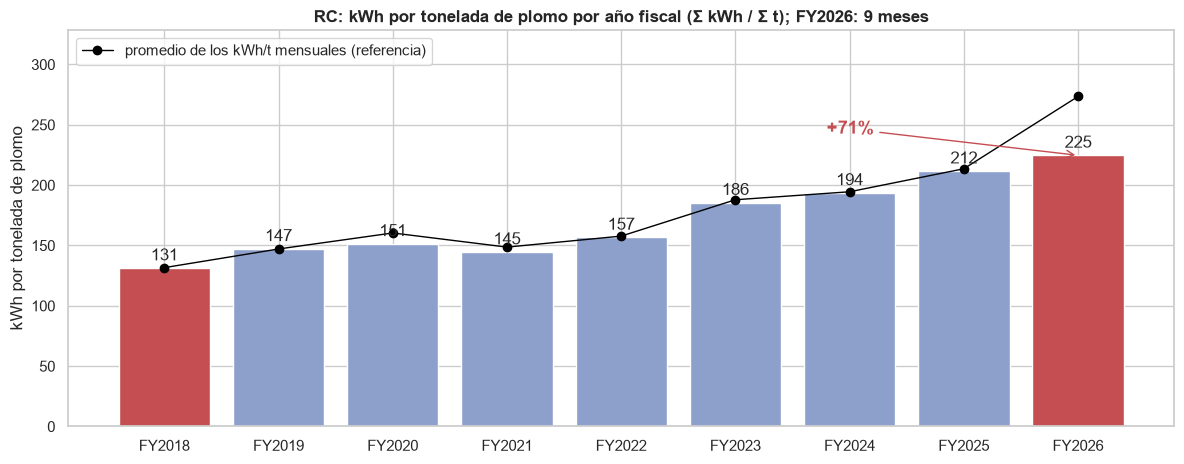

In [6]:
fig, axis = plt.subplots(figsize=(12, 4.8))
colors = ["#C44E52" if label in (first_fy, last_fy) else "#8DA0CB" for label in rc_steps.index]
bars = axis.bar(rc_steps.index, rc_steps["kwh_t_suma_sobre_suma"], color=colors)
axis.bar_label(bars, labels=[f"{v:,.0f}" for v in rc_steps["kwh_t_suma_sobre_suma"]], padding=3)
axis.plot(
    rc_steps.index,
    rc_steps["kwh_t_promedio_mensual"],
    color="black",
    marker="o",
    lw=1,
    label="promedio de los kWh/t mensuales (referencia)",
)
axis.annotate(
    f"{end / start - 1:+.0%}",
    xy=(len(rc_steps) - 1, end),
    xytext=(len(rc_steps) - 3.2, end * 1.08),
    arrowprops={"arrowstyle": "->", "color": "#C44E52"},
    color="#C44E52",
    fontweight="bold",
    fontsize=13,
)
axis.set_ylim(0, rc_steps[["kwh_t_suma_sobre_suma", "kwh_t_promedio_mensual"]].max().max() * 1.2)
axis.set_ylabel("kWh por tonelada de plomo")
months_last = rc_steps.loc[last_fy, "meses"]
axis.set_title(
    f"RC: kWh por tonelada de plomo por año fiscal (Σ kWh / Σ t); {last_fy}: {months_last} meses"
)
axis.legend(loc="upper left")
plt.tight_layout()
plt.show()

**Explicación técnica.**

* **FY2018:** 4,335,436 kWh ÷ 33,022 t = **131.29 kWh/t** (12 meses, oct-2017 a sep-2018).
* **FY2026:** 2,975,944 kWh ÷ 13,244 t = **224.71 kWh/t** (9 meses, oct-2025 a jun-2026).
* **Aumento:** 224.71 / 131.29 − 1 = **+71.2 %**. Comparando solo los mismos 9 meses calendario de FY2018 (126.47 kWh/t), el aumento es +77.7 %: que FY2026 esté incompleto no infla el resultado.
* **Unidades:** las toneladas del libro coinciden con el plomo refinado (`LEADPROD`) de la base de datos en los 9 meses de FY2026 (razón 1.00), así que son toneladas de plomo refinado.
* **Por qué Σ/Σ:** el promedio de los kWh/t mensuales coincide con Σ/Σ en casi todos los años, pero no en FY2026 (273.48 contra 224.71). Marzo (391 t) y abril (662 t) produjeron muy poco y tuvieron kWh/t altísimos, y el promedio simple les da el mismo peso que a un mes de 2,000 t. Σ/Σ es la cifra correcta.

**Lectura de negocio.** Cada tonelada de plomo que RC refinó en FY2026 costó 225 kWh, 93 más que en FY2018. La subida es escalonada: el salto grande ocurre en FY2023 (de 157 a 186) y desde entonces no ha vuelto atrás. Al ritmo de FY2026, unas 1,472 t al mes, esos kWh de más por tonelada son unos **137,000 kWh cada mes**.

## 2. ¿Cuándo cambió? Quiebres estructurales

Antes de medir cuánto empeoró cada área hay que saber **desde cuándo** comparar: una línea base ajustada sobre dos regímenes distintos no representa a ninguno. Se buscan fechas de quiebre en la relación `kWh ~ EQ + días` de cada área (y de RC con toneladas) con dos pruebas complementarias:

* **sup-F de Quandt-Andrews:** para cada mes candidato (recortando el 15 % de cada extremo) se calcula el estadístico F de Chow; el máximo indica el quiebre más probable. Su valor p se obtiene por **bootstrap de residuos** bajo la hipótesis nula de un solo régimen (499 réplicas), en vez de tablas asintóticas.
* **CUSUM de residuos recursivos:** si la suma acumulada de los errores de pronóstico un paso adelante sale de sus bandas del 5 %, la relación no es estable.

In [7]:
def chow_scan(frame: pd.DataFrame, trim: float = 0.15) -> tuple[pd.Series, np.ndarray, np.ndarray]:
    """Chow F for every admissible break month of kwh ~ 1 + eq + dias_c."""
    y = frame["kwh"].to_numpy()
    x = np.column_stack([np.ones(len(frame)), frame["eq"], frame["dias"] - frame["dias"].mean()])
    n, k = x.shape
    ssr_all = sm.OLS(y, x).fit().ssr
    lo, hi = int(np.floor(trim * n)), int(np.ceil((1 - trim) * n))
    stats_by_break = {}
    for b in range(max(lo, k + 1), min(hi, n - k - 1)):
        ssr_split = sm.OLS(y[:b], x[:b]).fit().ssr + sm.OLS(y[b:], x[b:]).fit().ssr
        stats_by_break[frame.index[b]] = ((ssr_all - ssr_split) / k) / (ssr_split / (n - 2 * k))
    return pd.Series(stats_by_break), x, y


def sup_f_bootstrap(frame: pd.DataFrame, n_boot: int = 499) -> tuple[pd.Series, float, float]:
    """Sup-F statistic and its residual-bootstrap p-value under a single regime."""
    scan, x, y = chow_scan(frame)
    fit = sm.OLS(y, x).fit()
    observed = scan.max()
    exceed = 0
    for _ in range(n_boot):
        y_star = fit.fittedvalues + RNG.choice(fit.resid, size=len(y), replace=True)
        boot = frame.assign(kwh=y_star)
        exceed += chow_scan(boot)[0].max() >= observed
    return scan, observed, (exceed + 1) / (n_boot + 1)


break_rows, scans = [], {}
for area in [*AREAS, "RC"]:
    frame = series[area]
    scan, observed, p_value = sup_f_bootstrap(frame)
    scans[area] = scan
    exog = np.column_stack([np.ones(len(frame)), frame["eq"], frame["dias"] - frame["dias"].mean()])
    ols = sm.OLS(frame["kwh"].to_numpy(), exog).fit()
    cusum_stat, cusum_p, _ = breaks_cusumolsresid(ols.resid, ddof=exog.shape[1])
    break_rows.append(
        {
            "area": area,
            "meses": len(frame),
            "quiebre_mas_probable": scan.idxmax().strftime("%Y-%m"),
            "FY_del_quiebre": rotulo_fiscal(anio_fiscal(pd.Series([scan.idxmax()])).iloc[0]),
            "sup_F": observed,
            "p_bootstrap": p_value,
            "CUSUM_estadistico": cusum_stat,
            "CUSUM_p": cusum_p,
        }
    )
breaks_table = pd.DataFrame(break_rows).set_index("area")
display(breaks_table)

,meses,quiebre_mas_probable,FY_del_quiebre,sup_F,p_bootstrap,CUSUM_estadistico,CUSUM_p
area,,,,,,,
Ensamble,82,2021-10,FY2022,23.17,0.00,2.35,0.00
OREC,81,2023-09,FY2023,7.77,0.00,2.03,0.00
F&A,82,2022-12,FY2023,1.66,0.72,0.73,0.67
RC,105,2022-10,FY2023,25.85,0.00,3.12,0.00


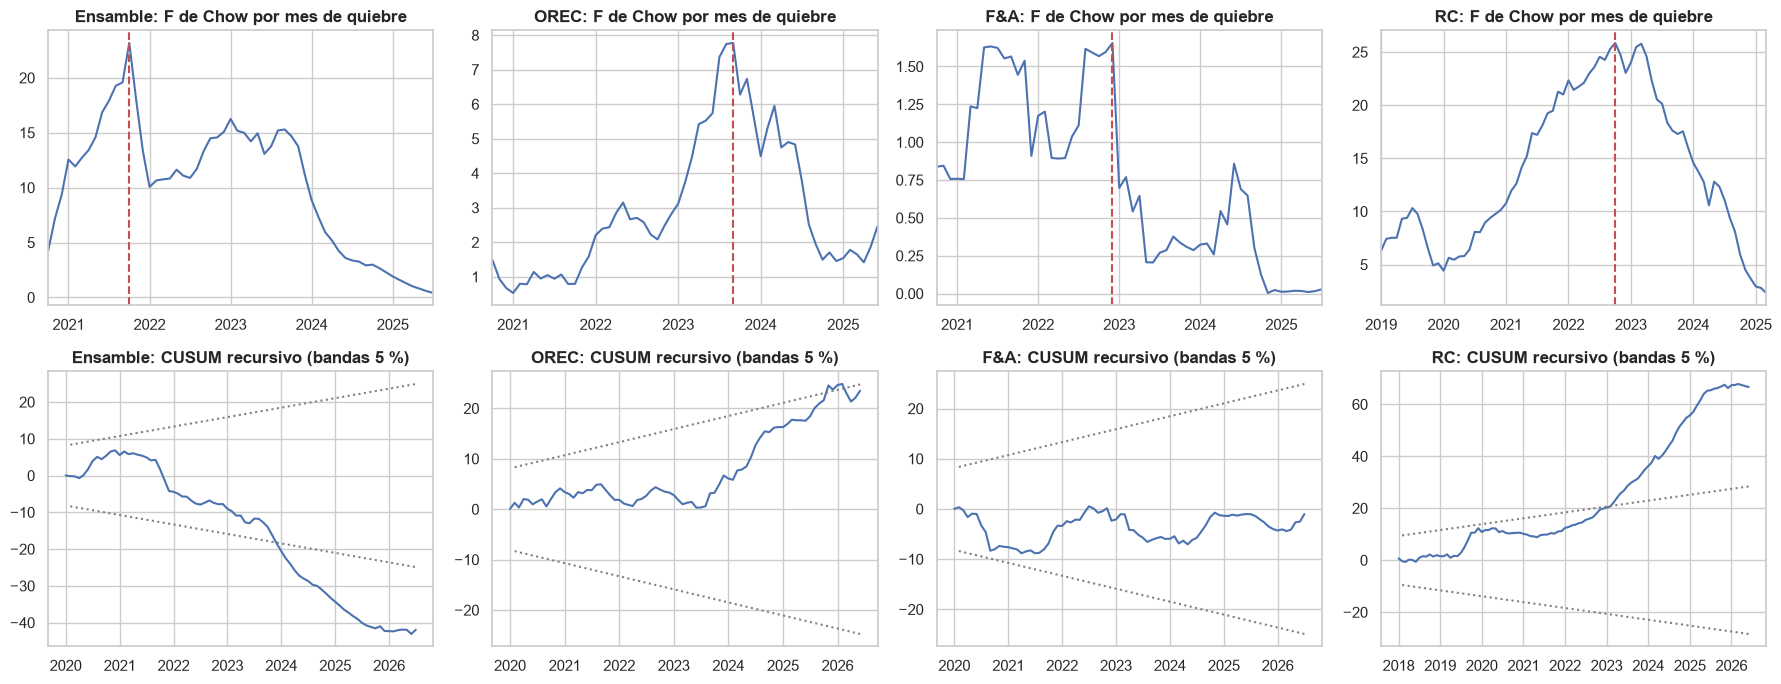

In [8]:
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for column, area in enumerate([*AREAS, "RC"]):
    scans[area].plot(ax=axes[0, column], color="#4C72B0")
    axes[0, column].axvline(scans[area].idxmax(), color="#C44E52", ls="--")
    axes[0, column].set_title(f"{area}: F de Chow por mes de quiebre")
    frame = series[area]
    exog = np.column_stack([np.ones(len(frame)), frame["eq"], frame["dias"] - frame["dias"].mean()])
    recursive = recursive_olsresiduals(
        sm.OLS(frame["kwh"].to_numpy(), exog).fit(), skip=exog.shape[1] + 1, alpha=0.95
    )
    cusum, bands = recursive[5], recursive[6]
    axes[1, column].plot(frame.index[-len(cusum) :], cusum, color="#4C72B0")
    for band in bands:
        axes[1, column].plot(frame.index[-len(band) :], band, color="grey", ls=":")
    axes[1, column].set_title(f"{area}: CUSUM recursivo (bandas 5 %)")
plt.tight_layout()
plt.show()

**Explicación técnica.** Tres de las cuatro áreas tienen un quiebre significativo en la relación energía-producción (p del bootstrap < 0.01 y CUSUM con p < 0.01):

| Área | Quiebre más probable | sup-F | Lectura del gráfico |
|---|---|---|---|
| Ensamble | oct-2021 (inicio de FY2022) | 23.2 | el kWh/EQ baja de ~2.7 a ~2.3: mejora |
| OREC | sep-2023 (fin de FY2023) | 7.8 | a partir de FY2024 la energía queda por encima de lo esperado |
| RC | oct-2022 (inicio de FY2023) | 25.9 | salto de 157 a 186 kWh/t |
| F&A | ninguno (sup-F 1.7, p 0.72; CUSUM p 0.67) | | relación estable en toda la historia |

**Lectura de negocio.** El problema no empezó en FY2026. OREC cambió de comportamiento al cerrar FY2023 y RC un año antes; F&A, en cambio, nunca cambió: su kWh/EQ solo se mueve con el volumen. Ensamble tuvo un cambio *favorable* en 2021, así que compararlo contra FY2020 subestima su eficiencia reciente; por eso su referencia es FY2022 a FY2023.

## 3. ¿Por qué sube el kWh/EQ? Volumen contra eficiencia

La energía de un área tiene una parte fija (iluminación, aire comprimido, hornos y sistemas que no se apagan) y una parte que crece con la producción. Si la producción baja, la parte fija se reparte entre menos EQ y el kWh/EQ sube **sin que el proceso sea menos eficiente**. Para separar ambos efectos se ajusta, en un periodo de referencia estable de cada área, una **línea base** al estilo ISO 50006:

$$kWh_t = \alpha + \beta\,EQ_t + \gamma\,(d\'ias_t - \bar d) + \varepsilon_t$$

El periodo de referencia sale de la sección 2: el tramo estable anterior al último quiebre que separa la etapa eficiente de la actual.

| Área | Referencia | Se evalúa desde | Por qué |
|---|---|---|---|
| Ensamble | FY2022 a FY2023 | FY2024 | quiebre en oct-2021: el régimen anterior era otro |
| OREC | FY2020 a FY2023 | FY2024 | quiebre en sep-2023 |
| F&A | FY2020 a FY2023 | FY2024 | sin quiebre: se usa el mismo corte que OREC |
| RC | FY2018 a FY2022 | FY2023 | quiebre en oct-2022 |

Con la línea base se calcula, para cada año posterior, el kWh/EQ que se esperaría **con el volumen real** de cada mes. El cambio frente a la referencia se descompone en:

* **efecto volumen** = kWh/EQ esperado con el volumen nuevo − kWh/EQ esperado en la referencia;
* **efecto desempeño** = kWh/EQ real − kWh/EQ esperado con el volumen nuevo (la pérdida o ganancia de eficiencia);
* un residuo de ajuste de la referencia, que debe ser casi cero.

In [9]:
# Stable reference of each area (section 2) and the first fiscal year evaluated against it
REFERENCE = {
    "Ensamble": (2022, 2023),
    "OREC": (2020, 2023),
    "F&A": (2020, 2023),
    "RC": (2018, 2022),
}
DECOMPOSED = [*AREAS, "RC"]


def baseline_fit(frame: pd.DataFrame, cov_lags: int = 3) -> tuple[RegressionResults, float]:
    """OLS kwh ~ 1 + eq + (dias - mean) with Newey-West errors."""
    design = pd.DataFrame(
        {"const": 1.0, "eq": frame["eq"], "dias_c": frame["dias"] - frame["dias"].mean()},
        index=frame.index,
    )
    return sm.OLS(frame["kwh"], design).fit(cov_type="HAC", cov_kwds={"maxlags": cov_lags}), frame[
        "dias"
    ].mean()


def baseline_predict(result: RegressionResults, mean_days: float, frame: pd.DataFrame) -> pd.Series:
    """Expected kWh of each month of frame under a fitted baseline."""
    design = pd.DataFrame(
        {"const": 1.0, "eq": frame["eq"], "dias_c": frame["dias"] - mean_days}, index=frame.index
    )
    return result.predict(design)


def reference_of(area: str, frame: pd.DataFrame) -> pd.DataFrame:
    """Months of the area's reference fiscal years."""
    return frame[frame["fy"].between(*REFERENCE[area])]


def after_of(area: str, frame: pd.DataFrame) -> pd.DataFrame:
    """Months after the area's reference fiscal years."""
    return frame[frame["fy"] > REFERENCE[area][1]]


baselines, coefficient_rows, test_rows = {}, [], []
for area in DECOMPOSED:
    reference = reference_of(area, series[area])
    fit, mean_days = baseline_fit(reference)
    baselines[area] = (fit, mean_days)
    ci = fit.conf_int()
    for name in fit.params.index:
        coefficient_rows.append(
            {
                "area": area,
                "termino": name,
                "coef": fit.params[name],
                "ee_HAC": fit.bse[name],
                "p": fit.pvalues[name],
                "ic95_inf": ci.loc[name, 0],
                "ic95_sup": ci.loc[name, 1],
            }
        )
    plain = sm.OLS(reference["kwh"], fit.model.exog).fit()
    tests = DiagnosticoOLS(plain).pruebas_hipotesis(mostrar=False).set_index("prueba")
    test_rows.append(
        {
            "area": area,
            "referencia": f"FY{REFERENCE[area][0]}-FY{REFERENCE[area][1]}",
            "n": int(fit.nobs),
            "R2": plain.rsquared,
            "JB_p": tests.loc["Jarque-Bera", "p_valor"],
            "BP_p": tests.loc["Breusch-Pagan", "p_valor"],
            "RESET_p": tests.loc["Ramsey RESET", "p_valor"],
            "DW": tests.loc["Durbin-Watson", "estadistico"],
            "LjungBox12_p": acorr_ljungbox(plain.resid, lags=[min(12, len(reference) // 3)])[
                "lb_pvalue"
            ].iloc[0],
        }
    )
print("Línea base de referencia de cada área, errores Newey-West (3 rezagos).")
print("En RC, 'eq' son toneladas de plomo:")
display(pd.DataFrame(coefficient_rows).set_index(["area", "termino"]))
print("Supuestos del ajuste de referencia:")
display(pd.DataFrame(test_rows).set_index("area"))

Línea base de referencia de cada área, errores Newey-West (3 rezagos).
En RC, 'eq' son toneladas de plomo:


coef    ee_HAC    p    ic95_inf   ic95_sup
area     termino                                                 
Ensamble const   219,098.68 57,741.05 0.00  105,928.30 332,269.06
         eq            0.53      0.51 0.29       -0.46       1.52
         dias_c    5,303.53  2,888.58 0.07     -357.99  10,965.05
OREC     const   141,813.64 15,602.95 0.00  111,232.42 172,394.87
         eq            4.30      0.16 0.00        3.98       4.62
         dias_c    7,436.61  3,484.83 0.03      606.48  14,266.75
F&A      const    87,659.60 97,372.75 0.37 -103,187.48 278,506.68
         eq           17.20      1.37 0.00       14.51      19.88
         dias_c   20,445.18 12,599.30 0.10   -4,249.00  45,139.36
RC       const    78,059.43 20,151.84 0.00   38,562.55 117,556.31
         eq          116.78      8.57 0.00       99.99     133.57
         dias_c   -8,337.98  6,026.42 0.17  -20,149.54   3,473.59

Supuestos del ajuste de referencia:


,referencia,n,R2,JB_p,BP_p,RESET_p,DW,LjungBox12_p
area,,,,,,,,
Ensamble,FY2022-FY2023,24,0.06,0.37,0.57,0.77,1.23,0.80
OREC,FY2020-FY2023,48,0.90,0.60,0.77,0.69,1.78,0.56
F&A,FY2020-FY2023,48,0.84,0.00,0.60,0.06,1.51,0.52
RC,FY2018-FY2022,60,0.48,0.15,0.51,0.99,1.63,0.03


In [10]:
def decompose(
    area: str, frame: pd.DataFrame, fit: RegressionResults, mean_days: float
) -> pd.DataFrame:
    """Volume / performance split of the change in kWh/EQ against the area's reference years."""
    frame = frame.assign(esperado=baseline_predict(fit, mean_days, frame))
    reference = reference_of(area, frame)
    actual_ref = reference["kwh"].sum() / reference["eq"].sum()
    expected_ref = reference["esperado"].sum() / reference["eq"].sum()
    rows = []
    for fy, group in after_of(area, frame).groupby("fy"):
        actual = group["kwh"].sum() / group["eq"].sum()
        expected = group["esperado"].sum() / group["eq"].sum()
        rows.append(
            {
                "fy": fy,
                "meses": len(group),
                "kwh_eq_ref": actual_ref,
                "kwh_eq_real": actual,
                "cambio": actual - actual_ref,
                "efecto_volumen": expected - expected_ref,
                "efecto_desempeno": actual - expected,
                "ajuste_ref": expected_ref - actual_ref,
                "kwh_exceso": group["kwh"].sum() - group["esperado"].sum(),
            }
        )
    return pd.DataFrame(rows)


def block_bootstrap_effects(
    area: str, frame: pd.DataFrame, n_boot: int = N_BOOT, block: int = 6
) -> pd.DataFrame:
    """Moving-block bootstrap of the reference months; refit and recompute the split."""
    reference = reference_of(area, frame)
    n = len(reference)
    starts = np.arange(n - block + 1)
    draws = []
    for _ in range(n_boot):
        index = np.concatenate(
            [np.arange(s, s + block) for s in RNG.choice(starts, size=n // block + 1)]
        )[:n]
        fit, mean_days = baseline_fit(reference.iloc[index])
        split = decompose(area, frame, fit, mean_days)
        draws.append(split[["fy", "efecto_volumen", "efecto_desempeno"]])
    return pd.concat(draws).groupby("fy").quantile([0.05, 0.95]).unstack()


decomposition = []
for area in DECOMPOSED:
    fit, mean_days = baselines[area]
    split = decompose(area, series[area], fit, mean_days)
    bands = block_bootstrap_effects(area, series[area])
    for effect, label in [
        ("efecto_volumen", "volumen_ic90"),
        ("efecto_desempeno", "desempeno_ic90"),
    ]:
        split[label] = [
            f"[{bands.loc[fy, (effect, 0.05)]:.2f}, {bands.loc[fy, (effect, 0.95)]:.2f}]"
            for fy in split["fy"]
        ]
    split.insert(0, "area", area)
    decomposition.append(split)
decomposition = pd.concat(decomposition, ignore_index=True)
decomposition["fy"] = decomposition["fy"].map(rotulo_fiscal)
decomposition["participacion_volumen"] = decomposition["efecto_volumen"] / decomposition["cambio"]
decomposition["suma_check"] = (
    decomposition["efecto_volumen"]
    + decomposition["efecto_desempeno"]
    + decomposition["ajuste_ref"]
    - decomposition["cambio"]
)
print("Cambio del kWh/EQ (RC: kWh por tonelada) frente a la referencia de cada área:")
display(decomposition.set_index(["area", "fy"]))

# Robustness: Ensamble with the common reference FY2020-FY2023, which spans its 2021 break
own_reference = REFERENCE["Ensamble"]
try:
    REFERENCE["Ensamble"] = (2020, 2023)
    fit_alt, days_alt = baseline_fit(reference_of("Ensamble", series["Ensamble"]))
    ensamble_alt = decompose("Ensamble", series["Ensamble"], fit_alt, days_alt)
finally:
    REFERENCE["Ensamble"] = own_reference
ensamble_alt["fy"] = ensamble_alt["fy"].map(rotulo_fiscal)
print("Sensibilidad: Ensamble con la referencia común FY2020-FY2023:")
display(
    ensamble_alt.set_index("fy")[
        ["kwh_eq_ref", "kwh_eq_real", "cambio", "efecto_volumen", "efecto_desempeno"]
    ]
)

Cambio del kWh/EQ (RC: kWh por tonelada) frente a la referencia de cada área:


meses  kwh_eq_ref  kwh_eq_real  cambio  efecto_volumen  efecto_desempeno  ajuste_ref   kwh_exceso    volumen_ic90  desempeno_ic90  participacion_volumen  suma_check
area     fy                                                                                                                                                                          
Ensamble FY2024     12        2.37         2.02   -0.34           -0.11             -0.23        0.00  -353,165.32  [-0.22, -0.07]  [-0.34, -0.14]                   0.33        0.00
         FY2025     12        2.37         2.06   -0.31           -0.15             -0.16        0.00  -250,472.13  [-0.28, -0.09]  [-0.27, -0.05]                   0.48        0.00
         FY2026     10        2.37         3.07    0.70            1.13             -0.43        0.00  -316,714.77    [0.72, 2.19]  [-1.55, -0.01]                   1.61        0.00
OREC     FY2024     12        5.76         5.95    0.19           -0.12              0.30       -0.00   388,142.64  [-0.13, -0.09]    [0.25, 0.37]                  -0.61        0.00
         FY2025     12        5.76         5.86    0.11           -0.10              0.21       -0.00   260,329.23  [-0.11, -0.08]    [0.16, 0.28]                  -0.96        0.00
         FY2026      9        5.76         6.68    0.92            0.73              0.20       -0.00   115,395.89    [0.56, 0.82]    [0.11, 0.37]                   0.79        0.00
F&A      FY2024     12       18.47        18.87    0.40            0.07              0.33       -0.00   263,152.72   [-0.01, 0.19]   [-0.17, 0.82]                   0.16        0.00
         FY2025     12       18.47        18.98    0.50            0.18              0.33       -0.00   235,246.87   [-0.09, 0.67]   [-0.46, 0.91]                   0.35        0.00
         FY2026     10       18.47        19.33    0.85            0.49              0.36       -0.00   176,462.66   [-0.23, 1.85]   [-1.19, 1.29]                   0.58        0.00
RC       FY2023     12      146.17       185.51   39.34            2.60             36.74        0.00 1,077,862.10    [1.22, 3.66]  [29.02, 44.05]                   0.07        0.00
         FY2024     12      146.17       193.64   47.47           -0.39             47.86        0.00 1,534,412.54  [-0.59, -0.03]  [39.64, 54.60]                  -0.01        0.00
         FY2025     12      146.17       211.65   65.47            3.97             61.50        0.00 1,729,502.19    [1.89, 5.61]  [53.69, 69.10]                   0.06        0.00
         FY2026      9      146.17       224.71   78.53           24.22             54.31        0.00   719,321.69  [11.38, 34.10]  [42.11, 69.63]                   0.31        0.00

Sensibilidad: Ensamble con la referencia común FY2020-FY2023:


,kwh_eq_ref,kwh_eq_real,cambio,efecto_volumen,efecto_desempeno
fy,,,,,
FY2024,2.55,2.02,-0.52,-0.07,-0.45
FY2025,2.55,2.06,-0.49,-0.09,-0.40
FY2026,2.55,3.07,0.52,0.46,0.07


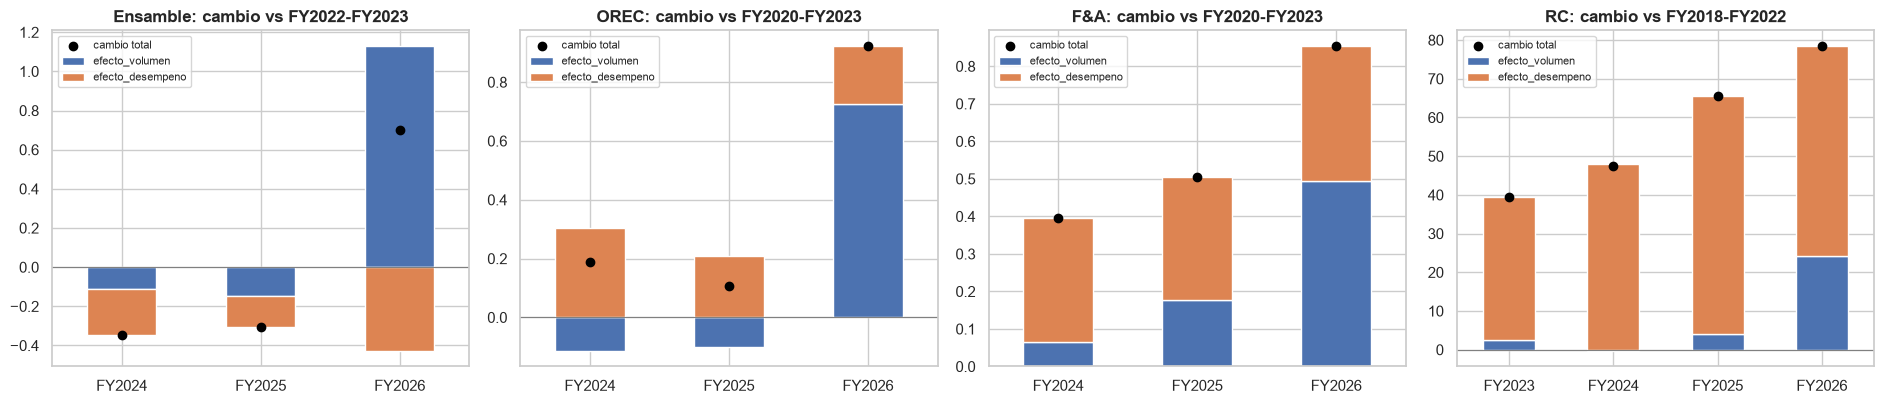

In [11]:
fig, axes = plt.subplots(1, 4, figsize=(19, 4.2))
for axis, area in zip(axes, DECOMPOSED, strict=True):
    part = decomposition[decomposition["area"] == area].set_index("fy")
    part[["efecto_volumen", "efecto_desempeno"]].plot.bar(
        ax=axis, stacked=True, color=["#4C72B0", "#DD8452"], rot=0
    )
    axis.scatter(range(len(part)), part["cambio"], color="black", zorder=3, label="cambio total")
    axis.axhline(0, color="grey", lw=0.8)
    axis.set_title(f"{area}: cambio vs FY{REFERENCE[area][0]}-FY{REFERENCE[area][1]}")
    axis.set_xlabel("")
    axis.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [12]:
# Did the relation itself change? Mean out-of-sample residual (HAC t),
# and a joint Wald test on the reference and later months
change_rows = []
for area in DECOMPOSED:
    fit, mean_days = baselines[area]
    frame = series[area][series[area]["fy"] >= REFERENCE[area][0]].copy()
    after = frame["fy"] > REFERENCE[area][1]
    residual = (frame["kwh"] - baseline_predict(fit, mean_days, frame))[after]
    mean_test = sm.OLS(residual.to_numpy(), np.ones(len(residual))).fit(
        cov_type="HAC", cov_kwds={"maxlags": 3}
    )
    post = after.astype(float)
    design = pd.DataFrame(
        {
            "const": 1.0,
            "eq": frame["eq"],
            "dias_c": frame["dias"] - frame["dias"].mean(),
            "post": post,
            "post_x_eq": post * frame["eq"],
        }
    )
    full = sm.OLS(frame["kwh"], design).fit(cov_type="HAC", cov_kwds={"maxlags": 3})
    wald = full.wald_test("post = 0, post_x_eq = 0", scalar=True)
    change_rows.append(
        {
            "area": area,
            "residuo_medio_kwh_mes": residual.mean(),
            "t_HAC": mean_test.tvalues[0],
            "p_residuo": mean_test.pvalues[0],
            "cambio_base_kwh_mes": full.params["post"],
            "p_base": full.pvalues["post"],
            "cambio_pendiente_kwh_eq": full.params["post_x_eq"],
            "p_pendiente": full.pvalues["post_x_eq"],
            "Wald_p_conjunto": float(wald.pvalue),
        }
    )
relation_change = pd.DataFrame(change_rows).set_index("area")
display(relation_change)

,residuo_medio_kwh_mes,t_HAC,p_residuo,cambio_base_kwh_mes,p_base,cambio_pendiente_kwh_eq,p_pendiente,Wald_p_conjunto
area,,,,,,,,
Ensamble,"-27,069.18",-7.78,0.00,"-47,195.44",0.43,0.18,0.73,0.00
OREC,"23,147.51",4.00,0.00,"-25,580.55",0.45,0.52,0.13,0.00
F&A,"19,848.89",1.37,0.17,"50,209.57",0.71,-0.51,0.80,0.76
RC,"112,468.86",9.87,0.00,"91,521.71",0.00,9.16,0.52,0.00


**Explicación técnica.**

* **Ensamble.** En su referencia (FY2022 a FY2023) la energía casi no depende del volumen: 219,099 kWh/mes fijos y 0.53 kWh por EQ adicional (p = 0.29, R² 0.06). El aumento de FY2026 (+0.70 kWh/EQ, de 2.37 a 3.07) es **todo volumen**: efecto volumen +1.13 (IC90 [0.72, 2.19]) y desempeño −0.43 (IC90 [−1.55, −0.01]). Con la referencia común FY2020 a FY2023 la conclusión no cambia: volumen +0.46, desempeño +0.07.
* **OREC.** Hay **pérdida real de eficiencia desde FY2024**: desempeño +0.30, +0.21 y +0.20 kWh/EQ en FY2024, FY2025 y FY2026, con los tres intervalos por encima de cero, y un residuo medio de +23,148 kWh/mes (t HAC 4.0, p < 0.001). En FY2026 el volumen explica 0.73 de los +0.92 (79 %).
* **F&A.** Ningún efecto es significativo: residuo medio p = 0.17, Wald conjunto p = 0.76, intervalos amplios que cruzan cero.
* **RC.** El aumento es **casi todo desempeño**: +36.7, +47.9, +61.5 y +54.3 kWh/t en FY2023 a FY2026, contra efectos de volumen de −0.4 a +24.2. Su carga fija subió 91,522 kWh/mes (p < 0.001) y el residuo medio es +112,469 kWh/mes (t 9.9).
* **Supuestos.** El ajuste de OREC es bueno en todas las pruebas (R² 0.90). F&A tiene residuos no normales (Jarque-Bera p < 0.01) y RC autocorrelación (Ljung-Box p = 0.03); por eso los errores son Newey-West y los intervalos salen de un bootstrap por bloques, que no supone normalidad ni independencia.

**Lectura de negocio.** El mismo indicador sube por razones distintas en cada área:

* **Ensamble no es menos eficiente, está subutilizado.** Gasta unos 220 MWh al mes casi sin importar cuánto ensambla; en FY2026 produjo 73,780 EQ/mes en promedio, frente a 139,698 en su mejor mes. Bajar su kWh/EQ exige volumen o apagar cargas fijas (por ejemplo la Línea 3, que dejó de producir y sigue recibiendo energía).
* **OREC tiene dos causas:** el volumen (la mayor parte en FY2026) y una pérdida persistente de unos 0.2 a 0.3 kWh/EQ que empezó en sep-2023 y no se ha corregido.
* **F&A está estable.** Su aumento es compatible con el volumen.
* **RC es el verdadero problema de eficiencia.** Gasta 54 kWh más por tonelada de los que su propia historia predice para el volumen que produce.

## 4. Cruces de fuentes

### 4.1 RC: energía y gas por tonelada en la historia larga (FY2018 a FY2026)

`eda_rc_energia` mostró que los kWh de RC bajan, pero sin producción no pudo hablar de intensidad. El libro de energía sí trae la producción de RC (toneladas de plomo) desde FY2018, y la hoja de gas los m³. Se cruzan aquí.

,kwh,m3,toneladas,kwh_t,m3_t
FY2018,"4,335,436.00","2,115,357.00","33,022.00",131.29,64.06
FY2019,"4,793,113.20","2,173,919.00","32,547.00",147.27,66.79
FY2020,"4,634,605.22","1,805,875.00","30,612.00",151.40,58.99
FY2021,"4,393,010.00","1,616,072.00","30,383.03",144.59,53.19
FY2022,"5,134,425.00","1,952,402.00","32,771.50",156.67,59.58
FY2023,"5,441,819.03","2,567,381.82","29,333.87",185.51,87.52
FY2024,"6,208,816.50","3,147,767.16","32,063.69",193.64,98.17
FY2025,"5,951,904.26","2,417,505.61","28,121.71",211.65,85.97
FY2026,"2,975,943.61","1,468,280.16","13,243.69",224.71,110.87


,estadistico,p
prueba,,
Tendencia kWh/t (Spearman vs tiempo),0.71,0.00
Tendencia m³/t (Spearman vs tiempo),0.46,0.00
Tendencia de toneladas (Spearman vs tiempo),-0.45,0.00
kWh/t FY2024-26 > FY2018-21 (Mann-Whitney),"1,448.00",0.00
m³/t FY2024-26 vs FY2018-21 (Mann-Whitney),"1,340.00",0.00
kWh/t y m³/t se mueven juntos (Spearman),0.73,0.00


Línea base RC (toda la historia): kWh = 195,890 + 88.9·t
p de la pendiente 9.48e-10, R² 0.28


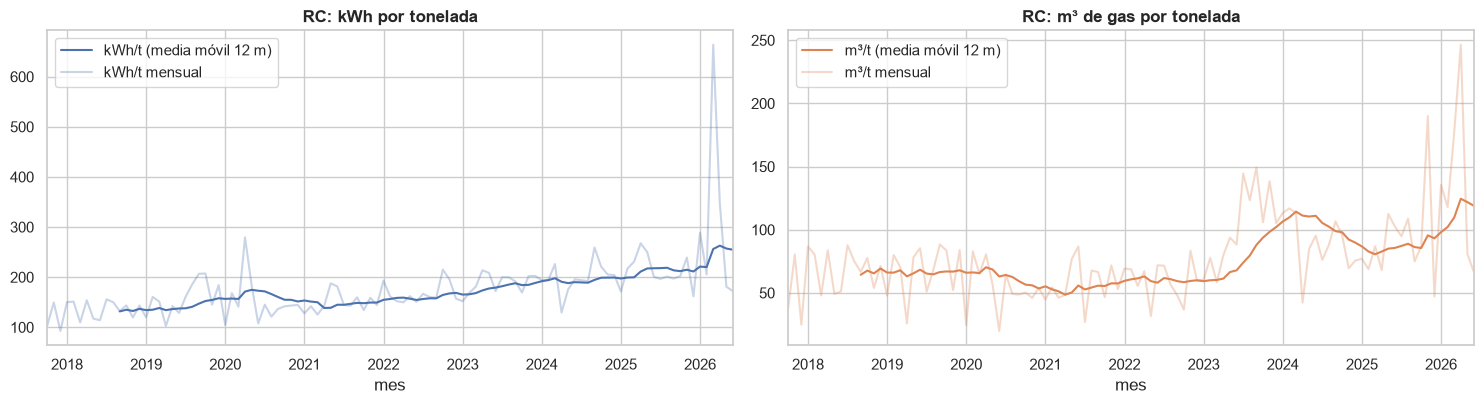

In [13]:
rc = series["RC"][["kwh", "eq", "dias", "fy"]].rename(columns={"eq": "toneladas"})
rc_gas = series["RC gas"][["kwh"]].rename(columns={"kwh": "m3"})
rc = rc.join(rc_gas, how="left")
rc["kwh_t"] = rc["kwh"] / rc["toneladas"]
rc["m3_t"] = rc["m3"] / rc["toneladas"]
rc_yearly = rc.groupby("fy")[["kwh", "m3", "toneladas"]].sum()
rc_yearly["kwh_t"] = rc_yearly["kwh"] / rc_yearly["toneladas"]
rc_yearly["m3_t"] = rc_yearly["m3"] / rc_yearly["toneladas"]
rc_yearly.index = [rotulo_fiscal(fy) for fy in rc_yearly.index]
display(rc_yearly)

time_index = np.arange(len(rc))
rho_kwh = stats.spearmanr(time_index, rc["kwh_t"], nan_policy="omit")
rho_gas = stats.spearmanr(time_index, rc["m3_t"], nan_policy="omit")
rho_tonnes = stats.spearmanr(time_index, rc["toneladas"], nan_policy="omit")
early, late = rc[rc["fy"] <= RC_EARLY_LAST_FY], rc[rc["fy"] >= RC_LATE_FIRST_FY]
mw_kwh = stats.mannwhitneyu(late["kwh_t"], early["kwh_t"], alternative="greater")
mw_gas = stats.mannwhitneyu(late["m3_t"].dropna(), early["m3_t"].dropna(), alternative="two-sided")
co_move = stats.spearmanr(rc["kwh_t"], rc["m3_t"], nan_policy="omit")
rc_fit = sm.OLS(
    rc["kwh"],
    sm.add_constant(
        pd.DataFrame({"toneladas": rc["toneladas"], "dias_c": rc["dias"] - rc["dias"].mean()})
    ),
).fit(cov_type="HAC", cov_kwds={"maxlags": 3})
rc_tests = pd.DataFrame(
    [
        {
            "prueba": "Tendencia kWh/t (Spearman vs tiempo)",
            "estadistico": rho_kwh.statistic,
            "p": rho_kwh.pvalue,
        },
        {
            "prueba": "Tendencia m³/t (Spearman vs tiempo)",
            "estadistico": rho_gas.statistic,
            "p": rho_gas.pvalue,
        },
        {
            "prueba": "Tendencia de toneladas (Spearman vs tiempo)",
            "estadistico": rho_tonnes.statistic,
            "p": rho_tonnes.pvalue,
        },
        {
            "prueba": "kWh/t FY2024-26 > FY2018-21 (Mann-Whitney)",
            "estadistico": mw_kwh.statistic,
            "p": mw_kwh.pvalue,
        },
        {
            "prueba": "m³/t FY2024-26 vs FY2018-21 (Mann-Whitney)",
            "estadistico": mw_gas.statistic,
            "p": mw_gas.pvalue,
        },
        {
            "prueba": "kWh/t y m³/t se mueven juntos (Spearman)",
            "estadistico": co_move.statistic,
            "p": co_move.pvalue,
        },
    ]
).set_index("prueba")
display(rc_tests)
rc_const, rc_slope = rc_fit.params["const"], rc_fit.params["toneladas"]
print(f"Línea base RC (toda la historia): kWh = {rc_const:,.0f} + {rc_slope:,.1f}·t")
print(f"p de la pendiente {rc_fit.pvalues['toneladas']:.3g}, R² {rc_fit.rsquared:.2f}")

fig, axes = plt.subplots(1, 2, figsize=(15, 4.2))
rc["kwh_t"].rolling(12).mean().plot(ax=axes[0], color="#4C72B0", label="kWh/t (media móvil 12 m)")
rc["kwh_t"].plot(ax=axes[0], color="#4C72B0", alpha=0.3, label="kWh/t mensual")
axes[0].set_title("RC: kWh por tonelada")
axes[0].legend()
rc["m3_t"].rolling(12).mean().plot(ax=axes[1], color="#DD8452", label="m³/t (media móvil 12 m)")
rc["m3_t"].plot(ax=axes[1], color="#DD8452", alpha=0.3, label="m³/t mensual")
axes[1].set_title("RC: m³ de gas por tonelada")
axes[1].legend()
plt.tight_layout()
plt.show()

**Explicación técnica.** Las tres tendencias son significativas (Spearman contra el tiempo, p < 0.001): kWh/t sube (ρ = 0.71), m³/t sube (ρ = 0.46) y las toneladas bajan (ρ = −0.45). El kWh/t de FY2024 a FY2026 es mayor que el de FY2018 a FY2021 (Mann-Whitney unilateral, p < 0.001). Lo más informativo: **kWh/t y m³/t se mueven juntos** mes a mes (ρ = 0.73, p < 0.001).

**Lectura de negocio.** Si solo subiera la electricidad podría ser un equipo eléctrico (un motor, un filtro) consumiendo de más. Que suban **a la vez la electricidad y el gas por tonelada** apunta a una causa del proceso: menos plomo recuperado por cada carga de horno, chatarra de menor ley, ciclos de refinación más largos o más arranques. Es la pregunta a llevarle a la planta.

### 4.2 SCADA de RC contra el libro, y cuánto consume RC cuando no produce

Los medidores de RC son contadores acumulados en Wh. Se convierten en energía por hora con la diferencia entre lecturas, descartando: lecturas en cero (medidor sin dato), pasos negativos (reinicios) y saltos físicamente imposibles (más de 3 veces el percentil 99.9 de la hora). EMCALI y EDIF ADMON quedan fuera: solo tienen lecturas desde mediados de 2026.

Para medir el consumo que no depende de producir se marcan como **horas de baja actividad** las horas en que la carga total de los siete medidores está por debajo del 40 % de la mediana horaria de su año fiscal (paradas, fines de semana, noches sin turno). Se mide cuánta energía se consume en esas horas y qué medidor la consume.

In [14]:
rc_raw = pd.read_excel(SCADA_RC, sheet_name="Dataset 1")
rc_raw["t_stamp"] = pd.to_datetime(rc_raw["t_stamp"])
rc_raw = rc_raw.sort_values("t_stamp").set_index("t_stamp")
PROCESS_METERS = ["FILTRO 1", "FILTRO 2", "HORNO", "REFINO 1", "REFINO 2", "TRITURADO", "PTARI"]
counters = rc_raw[PROCESS_METERS].replace(0, np.nan)
steps = counters.diff()
limit = steps[steps > 0].quantile(0.999) * 3
valid = (steps >= 0) & (steps <= limit)
hourly_kwh = steps.where(valid) / 1000
hourly_kwh.index = hourly_kwh.index.floor("h")
hourly_kwh = hourly_kwh.groupby(level=0).sum(min_count=1)
coverage_hours = hourly_kwh.notna().mean()
print("Horas válidas por medidor:", coverage_hours.round(3).to_dict())

monthly_meters = hourly_kwh.resample("MS").sum(min_count=1)
valid_share = hourly_kwh.notna().resample("MS").mean()
monthly_meters = monthly_meters.where(valid_share >= MIN_VALID_SHARE)
monthly_meters["total_medidores"] = monthly_meters[PROCESS_METERS].sum(
    axis=1, min_count=len(PROCESS_METERS)
)
compare = monthly_meters[["total_medidores"]].join(rc[["kwh", "toneladas"]], how="inner").dropna()
compare["cobertura"] = compare["total_medidores"] / compare["kwh"]
share = compare["cobertura"]
print(f"Meses comparables: {len(compare)}")
print(
    f"Los medidores de proceso explican en mediana el {share.median():.1%} del kWh de RC del libro"
)
print(f"Rango mensual: {share.min():.1%} a {share.max():.1%}")
corr_meters = stats.pearsonr(compare["total_medidores"], compare["kwh"])
r_meters, p_meters = corr_meters.statistic, corr_meters.pvalue
print(f"Correlación mensual medidores vs libro: r = {r_meters:.2f} (p = {p_meters:.3g})")

total_hourly = (
    hourly_kwh[PROCESS_METERS].sum(axis=1, min_count=len(PROCESS_METERS)).loc[:"2026-09-30 23:59"]
)
LOW_ACTIVITY = 0.40
idle_rows, meter_idle = [], {}
fiscal = anio_fiscal(total_hourly.index.to_series()).to_numpy()
for fy, values in total_hourly.dropna().groupby(fiscal[total_hourly.notna().to_numpy()]):
    threshold = LOW_ACTIVITY * values.median()
    low = values < threshold
    idle_rows.append(
        {
            "fy": rotulo_fiscal(fy),
            "horas": len(values),
            "carga_mediana_kw": values.median(),
            "horas_baja_actividad_%": 100 * low.mean(),
            "energia_en_baja_actividad_%": 100 * values[low].sum() / values.sum(),
            "carga_media_baja_actividad_kw": values[low].mean(),
            "carga_baja_sobre_mediana_%": 100 * values[low].mean() / values.median(),
        }
    )
    meters = hourly_kwh.loc[values.index, PROCESS_METERS]
    meter_idle[rotulo_fiscal(fy)] = meters[low.to_numpy()].mean()
idle = pd.DataFrame(idle_rows).set_index("fy")
display(idle)
meter_idle = pd.DataFrame(meter_idle)
print("Carga media de cada medidor en las horas de baja actividad (kW):")
display(meter_idle)

Horas válidas por medidor: {'FILTRO 1': 0.999, 'FILTRO 2': 0.997, 'HORNO': 1.0, 'REFINO 1': 0.996, 'REFINO 2': 0.996, 'TRITURADO': 0.996, 'PTARI': 1.0}
Meses comparables: 32
Los medidores de proceso explican en mediana el 62.1% del kWh de RC del libro
Rango mensual: 30.2% a 123.6%
Correlación mensual medidores vs libro: r = 0.73 (p = 2.26e-06)


,horas,carga_mediana_kw,horas_baja_actividad_%,energia_en_baja_actividad_%,carga_media_baja_actividad_kw,carga_baja_sobre_mediana_%
fy,,,,,,
FY2024,8662,462.41,2.77,0.48,76.90,16.63
FY2025,8749,438.42,14.40,1.40,37.82,8.63
FY2026,8757,408.85,13.92,1.74,45.47,11.12


Carga media de cada medidor en las horas de baja actividad (kW):


,FY2024,FY2025,FY2026
FILTRO 1,13.07,1.00,2.44
FILTRO 2,2.90,4.16,3.51
HORNO,3.14,1.42,3.02
REFINO 1,6.42,1.67,2.43
REFINO 2,1.28,0.30,0.37
TRITURADO,28.75,16.24,13.76
PTARI,21.33,13.04,19.94


**Explicación técnica.** Los siete medidores de proceso explican en mediana el **62 %** del kWh que el libro asigna a RC (con meses entre 30 % y 124 %) y siguen su movimiento (r = 0.73, p < 0.001). Las horas de baja actividad pasaron del 2.8 % de las horas de FY2024 al 14.4 % en FY2025 y 13.9 % en FY2026, pero en ellas se consume muy poca energía (0.5 % a 1.7 % del total): la carga cae a 38 a 77 kW, del 8 % al 17 % de la mediana (409 a 462 kW). Lo que queda encendido en esas horas es sobre todo TRITURADO (14 a 29 kW) y PTARI (13 a 21 kW, la planta de tratamiento de agua).

**Lectura de negocio.**

* **RC sí se apaga cuando para.** Su kWh/t no sube por consumo ocioso, sino por energía gastada **mientras opera**, con menos toneladas saliendo.
* **Las paradas se quintuplicaron** desde FY2024, lo que encaja con más arranques y menos continuidad en los hornos.
* **Un tercio largo de la energía de RC no está medido** por los siete medidores. Para explicar el resto hace falta otro medidor, o saber qué alimenta el libro.

### 4.3 RC diario: energía de los medidores contra el plomo refinado (base de datos, FY2026)

La base de datos registra la producción de plomo refinado (`LEADPROD`, kg) por fecha efectiva. Se cruza con la energía diaria de los medidores de RC. Como el plomo se asienta por lotes, también se usa una ventana móvil de 7 días.

In [15]:
lead = query(
    """
    SELECT fecha_efectiva AS dia, sum(valor) AS kg
    FROM gold.v_reporte_qad_regla
    WHERE cuenta_stats = 'LEADPROD' AND en_vigor
    GROUP BY 1
    """
)
lead["dia"] = pd.to_datetime(lead["dia"])
lead = (
    lead.set_index("dia")["kg"]
    .astype(float)
    .reindex(pd.date_range("2025-10-01", "2026-09-30", freq="D"))
    .fillna(0.0)
)
rc_daily_kwh = total_hourly.resample("D").sum(min_count=20)
rc_daily = (
    pd.DataFrame({"kwh": rc_daily_kwh, "kg_plomo": lead}).loc["2025-10-01":"2026-09-30"].dropna()
)
rc_daily["kwh_7d"] = rc_daily["kwh"].rolling(7).sum()
rc_daily["kg_7d"] = rc_daily["kg_plomo"].rolling(7).sum()
days_with_lead = (rc_daily["kg_plomo"] > 0).sum()
print(f"Días con energía de RC: {len(rc_daily)}; días con plomo asentado: {days_with_lead}")
daily_corr = stats.spearmanr(rc_daily["kwh"], rc_daily["kg_plomo"])
weekly = rc_daily.dropna()
weekly_corr = stats.spearmanr(weekly["kwh_7d"], weekly["kg_7d"])
weekly_fit = sm.OLS(weekly["kwh_7d"], sm.add_constant(weekly["kg_7d"] / 1000)).fit(
    cov_type="HAC", cov_kwds={"maxlags": 7}
)
print(f"Spearman diario kWh vs kg: {daily_corr.statistic:.2f} (p {daily_corr.pvalue:.3g})")
print(f"Spearman 7 días kWh vs kg: {weekly_corr.statistic:.2f} (p {weekly_corr.pvalue:.3g})")
week_const, week_slope = weekly_fit.params["const"], weekly_fit.params["kg_7d"]
print(f"Regresión 7 días (HAC 7): kWh_7d = {week_const:,.0f} + {week_slope:,.1f}·t_7d")
print(f"R² {weekly_fit.rsquared:.2f}")
fixed_share = week_const / weekly["kwh_7d"].mean()
print(f"La constante equivale a {fixed_share:.0%} de la energía de una semana media")

Días con energía de RC: 365; días con plomo asentado: 175
Spearman diario kWh vs kg: 0.31 (p 1.3e-09)
Spearman 7 días kWh vs kg: 0.44 (p 4.88e-18)
Regresión 7 días (HAC 7): kWh_7d = 50,349 + 31.0·t_7d
R² 0.17
La constante equivale a 83% de la energía de una semana media


**Explicación técnica.** Solo 175 de los 365 días de FY2026 tienen plomo asentado en QAD: se registra por lotes. Día a día la energía y el plomo apenas se relacionan (Spearman 0.31); en ventanas de 7 días un poco más (0.44, p < 0.001). La regresión semanal da una constante de 50,349 kWh más 31.0 kWh por tonelada (R² 0.17): **la constante equivale al 83 % de la energía de una semana media**.

**Lectura de negocio.** En FY2026 la energía de RC casi no sigue al plomo que se reporta. Hay dos explicaciones posibles, y las dos importan: o el plomo se asienta con días de retraso, o la mayor parte de la energía de RC no depende de cuánto plomo sale. En ambos casos el kWh/t mensual es un indicador ruidoso; conviene seguirlo como **promedio móvil de tres meses** y pedir que el plomo se registre el día en que se produce.

### 4.4 La cadena de suministro entre áreas

El plomo de RC alimenta a OREC (óxido, rejillas, placas), OREC a Ensamble y Ensamble a F&A. Si una caída de producción aguas arriba se transmite aguas abajo, las series de producción deben adelantarse unas a otras. Se prueba con **causalidad de Granger** sobre las variaciones logarítmicas mensuales (estacionarias según ADF), FY2020 a FY2026.

In [16]:
production = pd.DataFrame({area: series[area]["eq"] for area in AREAS}).join(
    series["RC"]["eq"].rename("RC")
)
production = production.loc["2019-10-01":].dropna()
growth = np.log(production).diff().dropna()
adf_rows = [
    {
        "serie": c,
        "ADF_p_nivel": adfuller(np.log(production[c]))[1],
        "ADF_p_variacion": adfuller(growth[c])[1],
    }
    for c in growth
]
display(pd.DataFrame(adf_rows).set_index("serie"))

pairs = [
    ("RC", "OREC"),
    ("OREC", "Ensamble"),
    ("Ensamble", "F&A"),
    ("OREC", "RC"),
    ("Ensamble", "OREC"),
    ("F&A", "Ensamble"),
]
granger_rows = []
for cause, effect in pairs:
    result = grangercausalitytests(growth[[effect, cause]], maxlag=2)
    p_by_lag = {lag: result[lag][0]["ssr_ftest"][1] for lag in result}
    contemporaneous = stats.pearsonr(growth[cause], growth[effect])
    granger_rows.append(
        {
            "causa": cause,
            "efecto": effect,
            "p_Granger_rezago1": p_by_lag[1],
            "p_Granger_rezago2": p_by_lag[2],
            "corr_mismo_mes": contemporaneous.statistic,
            "p_corr_mismo_mes": contemporaneous.pvalue,
            "corr(efecto t+1, causa t)": ccf(
                growth[effect], growth[cause], adjusted=False, nlags=3
            )[1],
        }
    )
granger = pd.DataFrame(granger_rows).set_index(["causa", "efecto"])
display(granger)

,ADF_p_nivel,ADF_p_variacion
serie,,
Ensamble,0.07,0.00
OREC,0.07,0.00
F&A,0.00,0.00
RC,0.00,0.00


,,p_Granger_rezago1,p_Granger_rezago2,corr_mismo_mes,p_corr_mismo_mes,"corr(efecto t+1, causa t)"
causa,efecto,,,,,
RC,OREC,0.24,0.71,0.77,0.00,-0.22
OREC,Ensamble,0.03,0.01,0.93,0.00,-0.16
Ensamble,F&A,0.26,0.48,0.84,0.00,-0.17
OREC,RC,0.00,0.00,0.77,0.00,0.08
Ensamble,OREC,0.20,0.04,0.93,0.00,-0.22
F&A,Ensamble,0.42,0.73,0.84,0.00,-0.27


**Explicación técnica.** Todas las series de producción son estacionarias en variación logarítmica (ADF p < 0.01). Las áreas se mueven **juntas en el mismo mes**: la correlación de las variaciones es 0.77 entre RC y OREC, 0.93 entre OREC y Ensamble y 0.84 entre Ensamble y F&A. En causalidad de Granger:

* **OREC anticipa a RC** (p < 0.01 con 1 y 2 rezagos), mientras que RC **no** anticipa a OREC (p = 0.24 y 0.71).
* OREC anticipa a Ensamble (p = 0.03 y 0.01).
* Ensamble no anticipa a F&A (p = 0.26 y 0.48).

**Lectura de negocio.** La planta trabaja **sincronizada con el plan del mes**: cuando baja una área bajan todas. La cadena es de *arrastre*: lo que OREC consume hoy anticipa lo que RC refina después, y no al revés. Las toneladas más bajas de RC son consecuencia de menos demanda aguas abajo, no una restricción de suministro, y una caída de Ensamble no se explica por falta de plomo.

### 4.5 Costo: ¿tarifa o intensidad?

Desde feb-2024 el libro trae el costo por kWh. El costo por EQ es el producto de dos factores, **tarifa** (COP/kWh) por **intensidad** (kWh/EQ), así que su cambio entre dos años se reparte exactamente con la descomposición logarítmica (LMDI):

$$\Delta\frac{C}{EQ} = L\cdot\ln\frac{p_1}{p_0} + L\cdot\ln\frac{i_1}{i_0},\qquad L = \frac{(C/EQ)_1 - (C/EQ)_0}{\ln (C/EQ)_1 - \ln (C/EQ)_0}$$

Se comparan FY2025 y FY2026 con **los mismos meses calendario** (los que FY2026 tiene).

In [17]:
lmdi_rows = []
for area in AREAS:
    frame = series[area].dropna(subset=["costo_total"])
    current = frame[frame["fy"] == CURRENT_FY]
    months = current.index.month
    previous = frame[(frame["fy"] == PREVIOUS_FY) & frame.index.month.isin(months)]
    totals = {}
    for label, part in [("FY2025", previous), ("FY2026", current)]:
        totals[label] = {
            "tarifa": part["costo_total"].sum() / part["kwh"].sum(),
            "intensidad": part["kwh"].sum() / part["eq"].sum(),
            "costo_eq": part["costo_total"].sum() / part["eq"].sum(),
            "eq": part["eq"].sum(),
        }
    c0, c1 = totals["FY2025"]["costo_eq"], totals["FY2026"]["costo_eq"]
    weight = (c1 - c0) / (np.log(c1) - np.log(c0))
    tariff_effect = weight * np.log(totals["FY2026"]["tarifa"] / totals["FY2025"]["tarifa"])
    intensity_effect = weight * np.log(
        totals["FY2026"]["intensidad"] / totals["FY2025"]["intensidad"]
    )
    lmdi_rows.append(
        {
            "area": area,
            "meses_comparados": len(current),
            "COP_EQ_FY2025": c0,
            "COP_EQ_FY2026": c1,
            "cambio_COP_EQ": c1 - c0,
            "efecto_tarifa": tariff_effect,
            "efecto_intensidad": intensity_effect,
            "tarifa_FY2025": totals["FY2025"]["tarifa"],
            "tarifa_FY2026": totals["FY2026"]["tarifa"],
            "COP_extra_FY2026_por_intensidad": intensity_effect * totals["FY2026"]["eq"],
        }
    )
lmdi = pd.DataFrame(lmdi_rows).set_index("area")
lmdi["participacion_intensidad"] = lmdi["efecto_intensidad"] / lmdi["cambio_COP_EQ"]
display(lmdi)

,meses_comparados,COP_EQ_FY2025,COP_EQ_FY2026,cambio_COP_EQ,efecto_tarifa,efecto_intensidad,tarifa_FY2025,tarifa_FY2026,COP_extra_FY2026_por_intensidad,participacion_intensidad
area,,,,,,,,,,
Ensamble,10,998.80,"1,664.20",665.40,115.21,550.19,496.12,541.97,"405,926,581.61",0.83
OREC,9,"2,865.73","3,628.39",762.66,295.46,467.20,495.66,543.11,"271,946,810.96",0.61
F&A,10,"9,522.87","10,479.69",956.82,911.35,45.46,494.99,542.25,"22,299,441.57",0.05


**Explicación técnica.** Entre FY2025 y FY2026, en los mismos meses calendario, la tarifa subió 9.3 % (de 496 a 542 COP/kWh). La descomposición LMDI del costo por EQ:

| Área | COP/EQ FY2025 | COP/EQ FY2026 | Parte por intensidad |
|---|---|---|---|
| Ensamble | 999 | 1,664 | 83 % (+550 COP/EQ) |
| OREC | 2,866 | 3,628 | 61 % (+467) |
| F&A | 9,523 | 10,480 | 5 %, casi todo es tarifa (+911 de +957) |

Valorado sobre los EQ de FY2026, la intensidad agregó 406 millones de COP en Ensamble, 272 millones en OREC y 22 millones en F&A.

**Lectura de negocio.** Cerca de **700 millones de COP en 9 a 10 meses** se deben a gastar más kWh por EQ y no a la tarifa. En Ensamble y OREC esa parte es la mayor; como la sección 3 mostró que en Ensamble es volumen, la palanca allí es de **programación de la producción** (concentrar la carga en menos días o líneas), no de mantenimiento. En F&A el aumento es tarifa: lo gestiona compras de energía, no la operación.

### 4.6 Los EQ de la base de datos contra los del libro de energía (FY2026)

El kWh/EQ del libro usa la columna `Produccion (Equivalente)`. La base de datos calcula los EQ desde las transacciones de QAD con los factores de la ecuación. Si no coinciden, el indicador depende de qué EQ se use.

In [18]:
db_by_area = pd.DataFrame(
    {
        "Ensamble": eq_monthly_db["equs_ensamble"],
        "OREC": eq_monthly_db["equs_orec"],
        "F&A": eq_monthly_db["equs_formacion"] + eq_monthly_db["equs_decorado"],
    }
)
eq_rows = []
for area in AREAS:
    workbook_eq = series[area]["eq"]
    both = pd.DataFrame({"libro": workbook_eq, "base": db_by_area[area]}).dropna()
    ratio = both["base"] / both["libro"]
    wilcoxon = stats.wilcoxon(both["base"], both["libro"])
    eq_rows.append(
        {
            "area": area,
            "meses": len(both),
            "EQ_libro": both["libro"].sum(),
            "EQ_base": both["base"].sum(),
            "base_sobre_libro": both["base"].sum() / both["libro"].sum(),
            "razon_min": ratio.min(),
            "razon_max": ratio.max(),
            "Wilcoxon_p": wilcoxon.pvalue,
            "kWh_EQ_con_libro": series[area].loc[both.index, "kwh"].sum() / both["libro"].sum(),
            "kWh_EQ_con_base": series[area].loc[both.index, "kwh"].sum() / both["base"].sum(),
        }
    )
eq_compare = pd.DataFrame(eq_rows).set_index("area")
display(eq_compare)

,meses,EQ_libro,EQ_base,base_sobre_libro,razon_min,razon_max,Wilcoxon_p,kWh_EQ_con_libro,kWh_EQ_con_base
area,,,,,,,,,
Ensamble,10,"737,795.83","737,795.83",1.00,1.00,1.00,0.07,3.07,3.07
OREC,9,"582,074.99","582,074.99",1.00,1.00,1.00,0.12,6.68,6.68
F&A,10,"490,519.72","455,167.66",0.93,0.88,0.99,0.00,19.33,20.83


**Explicación técnica.** En Ensamble y OREC los EQ del libro de energía son idénticos a los de la base de datos (razón 1.00 todos los meses). En **F&A no**: la base da un 7 % menos (razón entre 0.88 y 0.99; Wilcoxon pareado, p < 0.01). Con los EQ de la base, el kWh/EQ de F&A de FY2026 es **20.83**, no 19.33.

**Lectura de negocio.** El indicador de F&A depende de qué EQ se use. Con los EQ de la ecuación oficial F&A está un 14 % por encima de su presupuesto (18.33), no un 5 %. Hay que acordar con la planta cuál es la fuente válida antes de fijar metas.

### 4.7 Mezcla de producto: ¿el aumento es mezcla o volumen? (base de datos, FY2026)

Una batería de camión pesa el doble que una de auto y la ecuación de EQ ya la pondera (factor 0.761 contra 0.354 en Ensamble). Aun así, la mezcla podría mover la energía por EQ si los factores no reflejan bien el consumo real. Se construyen, por mes y por día:

* **Ensamble:** participación de baterías de camión y peso neto medio de lo ensamblado;
* **F&A:** participación de baterías de camión formadas y kg de pasta positiva por batería formada;
* **OREC:** participación de las placas de camión y participación del óxido en los EQ del área.

Con solo 9 a 10 meses de energía en FY2026 la prueba mensual es débil; por eso se complementa con F&A **diario** (rectificadores, jul a sep-2026).

In [19]:
MIX_SQL = """
SELECT regla.fecha_efectiva AS dia, regla.cuenta_stats, sum(regla.valor) AS valor,
       sum(regla.valor * coalesce(qad.peso_neto, 0)) AS peso
FROM gold.v_reporte_qad_regla AS regla
LEFT JOIN gold.v_reporte_qad AS qad ON qad.numero_de_transaccion = regla.numero_de_transaccion
WHERE regla.en_vigor
GROUP BY 1, 2
"""
mix_raw = query(MIX_SQL)
mix_raw["dia"] = pd.to_datetime(mix_raw["dia"])
mix_raw[["valor", "peso"]] = mix_raw[["valor", "peso"]].astype(float)
quantities = mix_raw.pivot_table(
    index="dia", columns="cuenta_stats", values="valor", aggfunc="sum"
).fillna(0.0)
weights = mix_raw.pivot_table(
    index="dia", columns="cuenta_stats", values="peso", aggfunc="sum"
).fillna(0.0)


def mix_features(qty: pd.DataFrame, wgt: pd.DataFrame) -> pd.DataFrame:
    """Mix variables from per-account quantities (any period length)."""
    assembled = qty["COSPRODU_SLI"] + qty["COSPRODU_TRUCK"]
    formed = qty["FORM_PRD_SLI"] + qty["FORM_PRD_TRUCK"]
    plates = qty["PLATEPRD_SLI"] + qty["PLATEPRD_TRUCK"]
    orec_eq = sum(qty[c] * f for c, f in OREC_FACTORS.items())
    return pd.DataFrame(
        {
            "ens_camion": qty["COSPRODU_TRUCK"] / assembled,
            "ens_peso_kg": (wgt["COSPRODU_SLI"] + wgt["COSPRODU_TRUCK"]) / assembled,
            "fa_camion": qty["FORM_PRD_TRUCK"] / formed,
            "fa_pasta_kg_bat": qty["POS_ACT_MTL"] / formed,
            "orec_placa_camion": qty["PLATEPRD_TRUCK"] / plates,
            "orec_oxido_eq": qty["OXPROD_KG"] * OREC_FACTORS["OXPROD_KG"] / orec_eq,
        }
    ).replace([np.inf, -np.inf], np.nan)


factors = query(
    "SELECT cuenta_stats, factor FROM silver.factores_equ WHERE proceso = 'OREC' AND version = 1"
)
OREC_FACTORS = dict(zip(factors["cuenta_stats"], factors["factor"].astype(float), strict=True))
monthly_mix = mix_features(quantities.resample("MS").sum(), weights.resample("MS").sum())
display(monthly_mix)

,ens_camion,ens_peso_kg,fa_camion,fa_pasta_kg_bat,orec_placa_camion,orec_oxido_eq
dia,,,,,,
2025-10-01,0.03,9.31,0.08,3.32,0.07,0.20
2025-11-01,0.08,11.02,0.08,3.39,0.13,0.19
2025-12-01,0.06,10.99,0.07,3.08,0.06,0.21
2026-01-01,0.05,10.77,0.06,3.43,0.09,0.20
2026-02-01,0.06,10.39,0.06,3.15,0.15,0.20
2026-03-01,0.08,11.14,0.06,3.18,0.09,0.20
2026-04-01,0.09,11.51,0.09,3.28,0.14,0.20
2026-05-01,0.03,10.57,0.03,3.01,0.05,0.21
2026-06-01,0.05,10.91,0.05,3.12,0.12,0.20


In [20]:
MIX_BY_AREA = {
    "Ensamble": ["ens_camion", "ens_peso_kg"],
    "F&A": ["fa_camion", "fa_pasta_kg_bat"],
    "OREC": ["orec_placa_camion", "orec_oxido_eq"],
}


def permutation_p(
    y: np.ndarray, x_fixed: np.ndarray, x_test: np.ndarray, n_perm: int = 4999
) -> tuple[float, float]:
    """Two-sided permutation p-value of the coefficient of x_test given x_fixed."""
    design = np.column_stack([np.ones(len(y)), x_fixed, x_test])
    observed = sm.OLS(y, design).fit().params[-1]
    hits = 0
    for _ in range(n_perm):
        shuffled = np.column_stack([np.ones(len(y)), x_fixed, RNG.permutation(x_test)])
        hits += abs(sm.OLS(y, shuffled).fit().params[-1]) >= abs(observed)
    return observed, (hits + 1) / (n_perm + 1)


mix_rows = []
for area in AREAS:
    eq_db = db_by_area[area]
    frame = (
        pd.DataFrame({"kwh": series[area]["kwh"], "eq": eq_db})
        .join(monthly_mix[MIX_BY_AREA[area]])
        .dropna()
    )
    frame["kwh_eq"] = frame["kwh"] / frame["eq"]
    inverse_eq = 1 / frame["eq"]
    volume_only = sm.OLS(frame["kwh_eq"], sm.add_constant(inverse_eq.rename("inv_eq"))).fit()
    for variable in MIX_BY_AREA[area]:
        coef, p_perm = permutation_p(
            frame["kwh_eq"].to_numpy(), inverse_eq.to_numpy(), frame[variable].to_numpy()
        )
        with_mix = sm.OLS(
            frame["kwh_eq"],
            sm.add_constant(pd.DataFrame({"inv_eq": inverse_eq, variable: frame[variable]})),
        ).fit(cov_type="HAC", cov_kwds={"maxlags": 1})
        mix_rows.append(
            {
                "area": area,
                "variable_mezcla": variable,
                "meses": len(frame),
                "R2_solo_volumen": volume_only.rsquared,
                "R2_volumen_y_mezcla": with_mix.rsquared,
                "coef_mezcla": coef,
                "p_HAC": with_mix.pvalues[variable],
                "p_permutacion": p_perm,
                "corr_mezcla_volumen": stats.spearmanr(frame[variable], frame["eq"]).statistic,
            }
        )
mix_tests = pd.DataFrame(mix_rows).set_index(["area", "variable_mezcla"])
display(mix_tests)

meses  R2_solo_volumen  R2_volumen_y_mezcla  coef_mezcla  p_HAC  p_permutacion  corr_mezcla_volumen
area     variable_mezcla                                                                                                       
Ensamble ens_camion            10             0.85                 0.86         5.97   0.21           0.36                -0.64
         ens_peso_kg           10             0.85                 0.85         0.03   0.79           0.91                -0.70
OREC     orec_placa_camion      9             0.20                 0.23        -2.64   0.62           0.67                 0.17
         orec_oxido_eq          9             0.20                 0.22       -15.68   0.60           0.69                -0.63
F&A      fa_camion             10             0.10                 0.12       -10.09   0.55           0.71                -0.13
         fa_pasta_kg_bat       10             0.10                 0.23        -2.84   0.00           0.33                -0.05

In [21]:
# Daily F&A: rectifier energy (SCADA) against daily EQ and mix from the database
fa_raw = pd.read_excel(SCADA_FA, sheet_name="Dataset 1")
fa_raw["t_stamp"] = pd.to_datetime(fa_raw["t_stamp"])
fa_raw = fa_raw.sort_values("t_stamp").set_index("t_stamp")
RECTIFIERS = ["RECTIFICADOR 1", "RECTIFICADOR 2", "RECTIFICADOR 3"]
midnights = pd.date_range(fa_raw.index.min().ceil("D"), fa_raw.index.max().floor("D"), freq="D")
at_midnight = (
    fa_raw[RECTIFIERS]
    .reindex(fa_raw.index.union(midnights))
    .interpolate(method="time")
    .loc[midnights]
)
fa_daily_kwh = at_midnight.diff().shift(-1).iloc[:-1] / 1000
fa_daily_kwh.index.name = "dia"
frozen = fa_daily_kwh.le(0) & fa_daily_kwh.sum(axis=1).gt(1000).to_numpy()[:, None]
fa_daily_kwh = fa_daily_kwh.mask(frozen)
fa_daily = pd.DataFrame({"kwh": fa_daily_kwh.sum(axis=1, min_count=3)})
fa_daily["eq"] = daily_eq["FORMACION"] + daily_eq["DECORADO"]
daily_mix = mix_features(quantities, weights)
fa_daily = fa_daily.join(daily_mix[["fa_camion", "fa_pasta_kg_bat"]])
fa_daily["domingo"] = (fa_daily.index.dayofweek == SUNDAY).astype(float)
fa_daily["sin_eq"] = (fa_daily["eq"] <= 0).astype(float)
fa_model_data = fa_daily.dropna(subset=["kwh", "eq"])
print(f"Días de F&A con energía válida: {len(fa_model_data)} (de {len(fa_daily)})")
print(f"Días sin EQ entre ellos: {int(fa_model_data['sin_eq'].sum())}")

producing = fa_model_data[fa_model_data["eq"] > 0].dropna(subset=["fa_camion", "fa_pasta_kg_bat"])
fa_ols = sm.OLS(
    producing["kwh"], sm.add_constant(producing[["eq", "fa_camion", "fa_pasta_kg_bat"]])
).fit()
fa_hac = fa_ols.get_robustcov_results(cov_type="HAC", maxlags=7)
fa_coef = pd.DataFrame(
    {"coef": fa_hac.params, "ee_HAC": fa_hac.bse, "p_HAC": fa_hac.pvalues},
    index=fa_ols.params.index,
)
display(fa_coef)
display(DiagnosticoOLS(fa_ols).pruebas_hipotesis(mostrar=False).set_index("prueba"))
print(f"R² = {fa_ols.rsquared:.2f}; n = {int(fa_ols.nobs)}")

Días de F&A con energía válida: 88 (de 91)
Días sin EQ entre ellos: 18


,coef,ee_HAC,p_HAC
const,"11,575.09","5,080.88",0.03
eq,16.38,1.64,0.00
fa_camion,"-4,472.93","10,611.63",0.67
fa_pasta_kg_bat,-896.77,"2,005.75",0.66


,estadistico,p_valor,H0
prueba,,,
Jarque-Bera,1.60,0.45,normalidad
Breusch-Pagan,4.78,0.19,homocedasticidad
Ramsey RESET,27.87,0.00,forma funcional adecuada
Durbin-Watson,1.10,NaN,"sin autocorrelación de orden 1, lectura heurís..."


R² = 0.82; n = 65


**Explicación técnica.**

* **Mensual.** Ninguna variable de mezcla es significativa en ninguna área (p de permutación entre 0.33 y 0.91). El volumen solo (1/EQ) explica el 85 % de la variación mensual del kWh/EQ de Ensamble, pero solo el 20 % en OREC y el 10 % en F&A. En F&A la pasta por batería sale "significativa" con errores HAC (p < 0.01), pero no por permutación (p = 0.33): con 10 meses los errores HAC no son confiables y la permutación es la prueba a creer.
* **Diario, F&A** (65 días con producción y mezcla): kWh = 11,575 + 16.38·EQ (p < 0.001, R² 0.82). La participación de camión (p = 0.67) y la pasta por batería (p = 0.66) no aportan. Los residuos son normales y homocedásticos (Jarque-Bera p = 0.45, Breusch-Pagan p = 0.19), pero RESET (p < 0.001) y Durbin-Watson (1.10) muestran forma funcional incompleta y autocorrelación: queda algo diario sin modelar, como los arranques y paradas de los rectificadores.

**Lectura de negocio.** **No hay evidencia de que la mezcla de producto explique el aumento**, ni camión contra auto, ni peso, ni pasta por batería. Los factores de la ecuación de EQ ya ponderan bien la mezcla. Lo que mueve el kWh/EQ es el volumen y, en OREC y RC, una pérdida de eficiencia.

### 4.8 ¿Era alcanzable el presupuesto de FY2026?

Con la línea base, el kWh/EQ esperado en un mes es $\alpha/EQ + \beta + \gamma(d\'ias-\bar d)/EQ$. Despejando, el volumen que haría falta para llegar al presupuesto es $EQ^* = (\alpha + \gamma(d\'ias-\bar d)) / (presupuesto - \beta)$. Se compara $EQ^*$ con la historia de cada área. Se usan dos líneas base: la de referencia de la sección 3 y una ajustada en los últimos 24 meses (el régimen actual).

In [22]:
budget_rows = []
for area in AREAS:
    frame = series[area]
    budget = frame["presupuesto"].dropna()
    if budget.empty:
        continue
    target = budget.median()
    recent = frame[frame.index >= frame.index.max() - pd.DateOffset(months=23)]
    for label, (fit, _mean_days) in [
        (f"referencia FY{REFERENCE[area][0]}-FY{REFERENCE[area][1]}", baselines[area]),
        ("últimos 24 meses", baseline_fit(recent)),
    ]:
        alpha, beta = fit.params["const"], fit.params["eq"]
        needed = alpha / (target - beta) if target > beta else np.inf
        history = frame["eq"]
        budget_rows.append(
            {
                "area": area,
                "linea_base": label,
                "presupuesto_kwh_eq": target,
                "beta_kwh_por_EQ_marginal": beta,
                "EQ_mes_necesarios": needed,
                "EQ_mes_FY2026_real": frame.loc[frame["fy"] == CURRENT_FY, "eq"].mean(),
                "EQ_mes_maximo_historico": history.max(),
                "percentil_historico_de_EQ*": stats.percentileofscore(history, needed)
                if np.isfinite(needed)
                else 100.0,
            }
        )
budget_check = pd.DataFrame(budget_rows).set_index(["area", "linea_base"])
display(budget_check)

presupuesto_kwh_eq  beta_kwh_por_EQ_marginal  EQ_mes_necesarios  EQ_mes_FY2026_real  EQ_mes_maximo_historico  percentil_historico_de_EQ*
area     linea_base                                                                                                                                                        
Ensamble referencia FY2022-FY2023                2.01                      0.53         148,001.72           73,779.58               139,698.44                      100.00
         últimos 24 meses                        2.01                      0.80         137,114.73           73,779.58               139,698.44                       98.78
OREC     referencia FY2020-FY2023                5.86                      4.30          90,965.26           64,675.00               115,284.20                       22.22
         últimos 24 meses                        5.86                      4.83         113,023.54           64,675.00               115,284.20                       91.36
F&A      referencia FY2020-FY2023               18.33                     17.20          77,099.16           49,051.97                89,889.00                       87.80
         últimos 24 meses                       18.33                     18.88                inf           49,051.97                89,889.00                      100.00

**Explicación técnica.**

* **Ensamble** necesitaría 148,002 EQ/mes con su referencia y 137,115 con el régimen actual para llegar a 2.01 kWh/EQ: el percentil 99 a 100 de su historia, cuando el promedio de FY2026 fue 73,780.
* **OREC** con su eficiencia de referencia lo lograría con 90,965 EQ/mes (percentil 22: un volumen normal), pero con el régimen actual necesita 113,024 (percentil 91), cuando produjo 64,675.
* **F&A** con el régimen actual tiene un costo marginal de 18.88 kWh por EQ, mayor que el presupuesto (18.33): **no lo alcanza con ningún volumen**.

**Lectura de negocio.** El presupuesto de FY2026 **no era alcanzable** con los volúmenes que tuvo la planta en ninguna de las tres áreas. Supuso volúmenes (o eficiencias) que no existieron. Un presupuesto de kWh/EQ debería ser una **curva en función del volumen planeado** (la línea base), no un número fijo, porque con un mismo proceso la meta cambia según cuánto se produzca.

## 5. Modelos de series de tiempo

Se evalúan tres problemas, todos **fuera de muestra** con origen móvil (ventana creciente, pronóstico a un paso):

| Problema | Variable objetivo | Uso | Ventana de prueba |
|---|---|---|---|
| A | kWh mensual por área, conociendo EQ y días | Línea base de monitoreo (ISO 50006) | últimos 24 meses |
| B | kWh/EQ mensual por área, sin información del mes | Pronóstico para planear | últimos 24 meses |
| C | kWh diario de F&A, conociendo EQ del día | Monitoreo diario | últimos 30 días |

Métricas: MAE, WAPE (Σ|error| / Σ real), **MASE** (MAE dividido por el MAE del pronóstico ingenuo en la misma ventana; < 1 le gana al ingenuo) y cobertura del intervalo del 90 % cuando el modelo lo tiene. El mejor modelo se compara con el ingenuo con la prueba de **Diebold-Mariano** (pérdida cuadrática, corrección de Harvey) y sus errores con Ljung-Box.

In [23]:
Z90 = stats.norm.ppf(0.95)
Model = Callable[[pd.DataFrame, pd.DataFrame, str], tuple[float, float, float]]


def diebold_mariano(
    e_model: pd.Series, e_bench: pd.Series, horizon: int = 1
) -> tuple[float, float]:
    """DM test (squared loss) with the Harvey-Leybourne-Newbold small-sample correction."""
    d = np.asarray(e_model) ** 2 - np.asarray(e_bench) ** 2
    n = len(d)
    gamma0 = np.var(d, ddof=0)
    variance = (
        gamma0 + 2 * sum(np.cov(d[k:], d[:-k], ddof=0)[0, 1] for k in range(1, horizon))
    ) / n
    dm = d.mean() / np.sqrt(variance)
    correction = np.sqrt((n + 1 - 2 * horizon + horizon * (horizon - 1) / n) / n)
    statistic = dm * correction
    return statistic, 2 * stats.t.sf(abs(statistic), df=n - 1)


def evaluate(
    forecasts: dict[str, pd.DataFrame], actual: pd.Series, naive_name: str = "Ingenuo"
) -> pd.DataFrame:
    """MAE, WAPE, MASE against the naive forecast and 90 % interval coverage of each model."""
    rows = []
    naive_mae = (forecasts[naive_name]["pred"] - actual).abs().mean()
    for name, frame in forecasts.items():
        error = frame["pred"] - actual
        row = {
            "modelo": name,
            "MAE": error.abs().mean(),
            "WAPE_%": 100 * error.abs().sum() / actual.abs().sum(),
            "MASE": error.abs().mean() / naive_mae,
            "cobertura_90": np.nan,
        }
        if {"lo", "hi"} <= set(frame):
            row["cobertura_90"] = ((actual >= frame["lo"]) & (actual <= frame["hi"])).mean()
        rows.append(row)
    return pd.DataFrame(rows).set_index("modelo").sort_values("MASE")


def rolling_origin(
    frame: pd.DataFrame, target: str, test_size: int, models: dict[str, Model]
) -> dict[str, pd.DataFrame]:
    """One-step-ahead expanding-window forecasts for each model on the last test_size rows."""
    out = {name: [] for name in models}
    for position in range(len(frame) - test_size, len(frame)):
        train, test = frame.iloc[:position], frame.iloc[[position]]
        for name, model in models.items():
            pred, lo, hi = model(train, test, target)
            out[name].append({"t": test.index[0], "pred": pred, "lo": lo, "hi": hi})
    return {
        name: pd.DataFrame(rows).set_index("t").dropna(axis=1, how="all")
        for name, rows in out.items()
    }


def m_naive(train: pd.DataFrame, _test: pd.DataFrame, target: str) -> tuple[float, float, float]:
    """Last value."""
    return train[target].iloc[-1], np.nan, np.nan


def m_seasonal_naive(
    train: pd.DataFrame, _test: pd.DataFrame, target: str
) -> tuple[float, float, float]:
    """Same month one year earlier."""
    return train[target].iloc[-SEASON], np.nan, np.nan


def m_mean12(train: pd.DataFrame, _test: pd.DataFrame, target: str) -> tuple[float, float, float]:
    """Mean of the last 12 months."""
    return train[target].iloc[-SEASON:].mean(), np.nan, np.nan


def m_ets(train: pd.DataFrame, _test: pd.DataFrame, target: str) -> tuple[float, float, float]:
    """Additive ETS with a damped trend, with its 90 % interval."""
    fit = ETSModel(
        pd.Series(train[target].to_numpy()), error="add", trend="add", damped_trend=True
    ).fit(disp=False)
    forecast = fit.get_prediction(start=len(train), end=len(train)).summary_frame(alpha=0.10)
    return forecast["mean"].iloc[0], forecast["pi_lower"].iloc[0], forecast["pi_upper"].iloc[0]


def regressors(frame: pd.DataFrame, mean_days: float) -> pd.DataFrame:
    """Constant, EQ and centred days of each month."""
    return pd.DataFrame(
        {"const": 1.0, "eq": frame["eq"], "dias_c": frame["dias"] - mean_days}, index=frame.index
    )


def m_ols(train: pd.DataFrame, test: pd.DataFrame, target: str) -> tuple[float, float, float]:
    """OLS on EQ and days, with its 90 % prediction interval."""
    mean_days = train["dias"].mean()
    fit = sm.OLS(train[target], regressors(train, mean_days)).fit()
    forecast = fit.get_prediction(regressors(test, mean_days)).summary_frame(alpha=0.10)
    return (
        forecast["mean"].iloc[0],
        forecast["obs_ci_lower"].iloc[0],
        forecast["obs_ci_upper"].iloc[0],
    )


def m_ols_recent(
    train: pd.DataFrame, test: pd.DataFrame, target: str, window: int = 36
) -> tuple[float, float, float]:
    """The same OLS on the last `window` months only."""
    return m_ols(train.iloc[-window:], test, target)


def m_regarima(train: pd.DataFrame, test: pd.DataFrame, target: str) -> tuple[float, float, float]:
    """Regression on EQ and days with AR(1) errors."""
    mean_days = train["dias"].mean()
    fit = SARIMAX(train[target], exog=regressors(train, mean_days), order=(1, 0, 0)).fit(disp=False)
    forecast = fit.get_forecast(1, exog=regressors(test, mean_days)).summary_frame(alpha=0.10)
    return (
        forecast["mean"].iloc[0],
        forecast["mean_ci_lower"].iloc[0],
        forecast["mean_ci_upper"].iloc[0],
    )


def m_ar1(train: pd.DataFrame, _test: pd.DataFrame, target: str) -> tuple[float, float, float]:
    """AR(1) with a constant on the target alone."""
    fit = SARIMAX(train[target].to_numpy(), order=(1, 0, 0), trend="c").fit(disp=False)
    forecast = fit.get_forecast(1).summary_frame(alpha=0.10)
    return (
        forecast["mean"].iloc[0],
        forecast["mean_ci_lower"].iloc[0],
        forecast["mean_ci_upper"].iloc[0],
    )


MODELS_A = {
    "Ingenuo": m_naive,
    "Ingenuo estacional": m_seasonal_naive,
    "Media 12 meses": m_mean12,
    "ETS amortiguado": m_ets,
    "OLS EQ + días (ventana creciente)": m_ols,
    "OLS EQ + días (últimos 36 meses)": m_ols_recent,
    "Regresión con errores AR(1)": m_regarima,
}
MODELS_B = {
    "Ingenuo": m_naive,
    "Ingenuo estacional": m_seasonal_naive,
    "Media 12 meses": m_mean12,
    "ETS amortiguado": m_ets,
    "AR(1) con constante": m_ar1,
}

warnings.filterwarnings("ignore", module="statsmodels")
results_a, results_b, forecasts_a, best_rows = {}, {}, {}, []
for area in AREAS:
    frame = series[area][["kwh", "eq", "dias", "kwh_eq"]].dropna()
    forecasts = rolling_origin(frame, "kwh", 24, MODELS_A)
    actual = frame["kwh"].iloc[-24:]
    results_a[area] = evaluate(forecasts, actual)
    forecasts_a[area] = (forecasts, actual)
    forecasts_b = rolling_origin(frame, "kwh_eq", 24, MODELS_B)
    actual_b = frame["kwh_eq"].iloc[-24:]
    results_b[area] = evaluate(forecasts_b, actual_b)
    for problem, table, fc, act in [
        ("A", results_a[area], forecasts, actual),
        ("B", results_b[area], forecasts_b, actual_b),
    ]:
        best = table.index[0] if table.index[0] != "Ingenuo" else table.index[1]
        dm_stat, dm_p = diebold_mariano(fc[best]["pred"] - act, fc["Ingenuo"]["pred"] - act)
        lb_p = acorr_ljungbox((fc[best]["pred"] - act).to_numpy(), lags=[6])["lb_pvalue"].iloc[0]
        best_rows.append(
            {
                "problema": problem,
                "area": area,
                "mejor_modelo": best,
                "MASE": table.loc[best, "MASE"],
                "WAPE_%": table.loc[best, "WAPE_%"],
                "DM_vs_ingenuo": dm_stat,
                "DM_p": dm_p,
                "LjungBox6_p_errores": lb_p,
            }
        )

for area in AREAS:
    print(f"Problema A, {area}: kWh mensual conociendo EQ y días")
    display(results_a[area])
for area in AREAS:
    print(f"Problema B, {area}: kWh/EQ mensual sin información del mes")
    display(results_b[area])

Problema A, Ensamble: kWh mensual conociendo EQ y días


,MAE,WAPE_%,MASE,cobertura_90
modelo,,,,
OLS EQ + días (últimos 36 meses),"13,396.07",5.34,0.68,0.92
ETS amortiguado,"17,140.96",6.83,0.87,0.96
Regresión con errores AR(1),"19,271.30",7.68,0.98,0.92
Ingenuo,"19,640.92",7.82,1.00,NaN
Media 12 meses,"21,827.45",8.70,1.11,NaN
OLS EQ + días (ventana creciente),"25,397.44",10.12,1.29,1.00
Ingenuo estacional,"31,680.17",12.62,1.61,NaN


Problema A, OREC: kWh mensual conociendo EQ y días


,MAE,WAPE_%,MASE,cobertura_90
modelo,,,,
Regresión con errores AR(1),"26,498.64",4.79,0.47,0.79
OLS EQ + días (últimos 36 meses),"27,085.04",4.89,0.48,0.79
OLS EQ + días (ventana creciente),"27,288.26",4.93,0.48,0.83
ETS amortiguado,"54,109.33",9.78,0.96,0.92
Ingenuo,"56,516.83",10.21,1.00,NaN
Media 12 meses,"70,941.20",12.82,1.26,NaN
Ingenuo estacional,"118,855.63",21.48,2.10,NaN


Problema A, F&A: kWh mensual conociendo EQ y días


,MAE,WAPE_%,MASE,cobertura_90
modelo,,,,
Regresión con errores AR(1),"45,526.94",4.24,0.49,1.00
OLS EQ + días (ventana creciente),"50,704.35",4.72,0.55,1.00
OLS EQ + días (últimos 36 meses),"63,298.74",5.89,0.68,0.92
Ingenuo,"92,722.71",8.63,1.00,NaN
ETS amortiguado,"100,346.94",9.34,1.08,1.00
Media 12 meses,"124,709.51",11.61,1.34,NaN
Ingenuo estacional,"195,248.17",18.17,2.11,NaN


Problema B, Ensamble: kWh/EQ mensual sin información del mes


,MAE,WAPE_%,MASE,cobertura_90
modelo,,,,
ETS amortiguado,0.33,12.82,0.84,0.83
AR(1) con constante,0.36,14.04,0.92,0.88
Ingenuo,0.39,15.33,1.00,NaN
Media 12 meses,0.41,15.80,1.03,NaN
Ingenuo estacional,0.60,23.21,1.51,NaN


Problema B, OREC: kWh/EQ mensual sin información del mes


,MAE,WAPE_%,MASE,cobertura_90
modelo,,,,
AR(1) con constante,0.38,6.03,0.88,0.83
ETS amortiguado,0.38,6.16,0.90,0.83
Media 12 meses,0.39,6.19,0.90,NaN
Ingenuo,0.43,6.88,1.00,NaN
Ingenuo estacional,0.59,9.43,1.37,NaN


Problema B, F&A: kWh/EQ mensual sin información del mes


,MAE,WAPE_%,MASE,cobertura_90
modelo,,,,
AR(1) con constante,0.90,4.67,0.91,0.92
Media 12 meses,0.97,5.02,0.97,NaN
ETS amortiguado,0.97,5.04,0.98,0.88
Ingenuo,0.99,5.15,1.00,NaN
Ingenuo estacional,1.32,6.83,1.33,NaN


In [24]:
def d_naive(train: pd.DataFrame, _test: pd.DataFrame, target: str) -> tuple[float, float, float]:
    """Previous day."""
    return train[target].iloc[-1], np.nan, np.nan


def d_weekday_naive(
    train: pd.DataFrame, _test: pd.DataFrame, target: str
) -> tuple[float, float, float]:
    """Same weekday one week earlier."""
    return train[target].iloc[-WEEK], np.nan, np.nan


def daily_design(frame: pd.DataFrame) -> pd.DataFrame:
    """Constant, EQ, Sunday and no-EQ indicators of each day."""
    return pd.DataFrame(
        {"const": 1.0, "eq": frame["eq"], "domingo": frame["domingo"], "sin_eq": frame["sin_eq"]},
        index=frame.index,
    )


def d_ols(train: pd.DataFrame, test: pd.DataFrame, target: str) -> tuple[float, float, float]:
    """Daily OLS with its 90 % prediction interval."""
    fit = sm.OLS(train[target], daily_design(train)).fit()
    forecast = fit.get_prediction(daily_design(test)).summary_frame(alpha=0.10)
    return (
        forecast["mean"].iloc[0],
        forecast["obs_ci_lower"].iloc[0],
        forecast["obs_ci_upper"].iloc[0],
    )


def d_regarima(train: pd.DataFrame, test: pd.DataFrame, target: str) -> tuple[float, float, float]:
    """Daily regression with AR(1) errors."""
    fit = SARIMAX(
        train[target], exog=daily_design(train).drop(columns="const"), order=(1, 0, 0), trend="c"
    ).fit(disp=False)
    forecast = fit.get_forecast(1, exog=daily_design(test).drop(columns="const")).summary_frame(
        alpha=0.10
    )
    return (
        forecast["mean"].iloc[0],
        forecast["mean_ci_lower"].iloc[0],
        forecast["mean_ci_upper"].iloc[0],
    )


MODELS_C = {
    "Ingenuo": d_naive,
    "Ingenuo semanal": d_weekday_naive,
    "OLS EQ + domingo + sin EQ": d_ols,
    "Regresión con errores AR(1)": d_regarima,
}
fa_series = fa_model_data[["kwh", "eq", "domingo", "sin_eq"]]
fa_series = fa_series.asfreq("D").interpolate(limit=2).dropna()
forecasts_c = rolling_origin(fa_series, "kwh", 30, MODELS_C)
actual_c = fa_series["kwh"].iloc[-30:]
results_c = evaluate(forecasts_c, actual_c)
best_c = results_c.index[0] if results_c.index[0] != "Ingenuo" else results_c.index[1]
dm_c = diebold_mariano(
    forecasts_c[best_c]["pred"] - actual_c, forecasts_c["Ingenuo"]["pred"] - actual_c
)
best_rows.append(
    {
        "problema": "C",
        "area": "F&A diario",
        "mejor_modelo": best_c,
        "MASE": results_c.loc[best_c, "MASE"],
        "WAPE_%": results_c.loc[best_c, "WAPE_%"],
        "DM_vs_ingenuo": dm_c[0],
        "DM_p": dm_c[1],
        "LjungBox6_p_errores": acorr_ljungbox(
            (forecasts_c[best_c]["pred"] - actual_c).to_numpy(), lags=[6]
        )["lb_pvalue"].iloc[0],
    }
)
print("Problema C, F&A diario (rectificadores):")
display(results_c)
best_models = pd.DataFrame(best_rows).set_index(["problema", "area"])
print("Mejor modelo por problema y prueba de Diebold-Mariano contra el ingenuo:")
display(best_models)

Problema C, F&A diario (rectificadores):


,MAE,WAPE_%,MASE,cobertura_90
modelo,,,,
OLS EQ + domingo + sin EQ,"4,433.46",12.28,0.28,0.97
Regresión con errores AR(1),"5,269.06",14.59,0.33,0.83
Ingenuo semanal,"10,522.36",29.15,0.66,NaN
Ingenuo,"15,974.86",44.25,1.00,NaN


Mejor modelo por problema y prueba de Diebold-Mariano contra el ingenuo:


,,mejor_modelo,MASE,WAPE_%,DM_vs_ingenuo,DM_p,LjungBox6_p_errores
problema,area,,,,,,
A,Ensamble,OLS EQ + días (últimos 36 meses),0.68,5.34,-1.13,0.27,0.98
B,Ensamble,ETS amortiguado,0.84,12.82,-0.91,0.37,0.29
A,OREC,Regresión con errores AR(1),0.47,4.79,-2.30,0.03,0.82
B,OREC,AR(1) con constante,0.88,6.03,-0.45,0.65,0.29
A,F&A,Regresión con errores AR(1),0.49,4.24,-2.07,0.05,0.36
B,F&A,AR(1) con constante,0.91,4.67,-0.15,0.88,0.34
C,F&A diario,OLS EQ + domingo + sin EQ,0.28,12.28,-3.46,0.00,0.23


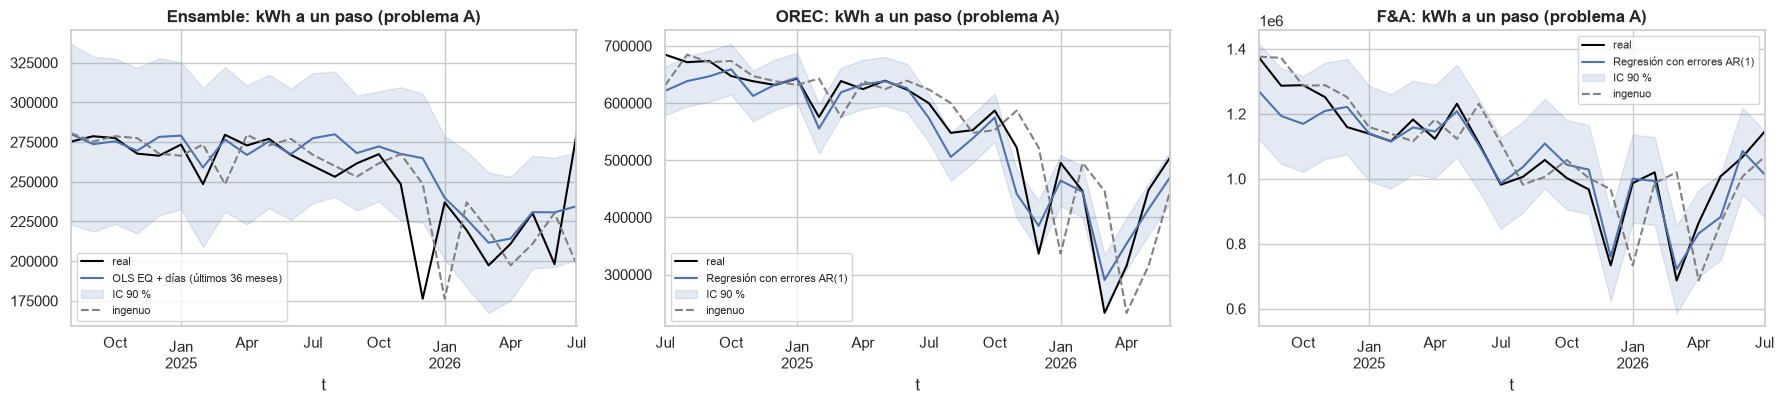

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.2))
for axis, area in zip(axes, AREAS, strict=True):
    forecasts, actual = forecasts_a[area]
    best = best_models.loc[("A", area), "mejor_modelo"]
    actual.plot(ax=axis, color="black", label="real")
    forecasts[best]["pred"].plot(ax=axis, color="#4C72B0", label=best)
    if {"lo", "hi"} <= set(forecasts[best]):
        axis.fill_between(
            forecasts[best].index,
            forecasts[best]["lo"],
            forecasts[best]["hi"],
            color="#4C72B0",
            alpha=0.15,
            label="IC 90 %",
        )
    forecasts["Ingenuo"]["pred"].plot(ax=axis, color="grey", ls="--", label="ingenuo")
    axis.set_title(f"{area}: kWh a un paso (problema A)")
    axis.legend(fontsize=8)
plt.tight_layout()
plt.show()

**Explicación técnica.**

* **Problema A** (kWh conociendo EQ y días). Los modelos de regresión le ganan al ingenuo: OREC, regresión con errores AR(1), MASE 0.47, WAPE 4.8 % (Diebold-Mariano p = 0.03); F&A, igual modelo, MASE 0.49, WAPE 4.2 % (p = 0.05); Ensamble, OLS con los últimos 36 meses, MASE 0.68, WAPE 5.3 % (p = 0.27, no significativo). En Ensamble la ventana creciente falla (MASE 1.29) porque mezcla los regímenes anteriores y posteriores al quiebre de 2021. Los intervalos del 90 % cubren entre 92 % y 100 % de los casos, salvo OREC (79 %): sus intervalos son algo estrechos.
* **Problema B** (kWh/EQ sin información del mes). Ningún modelo le gana con significancia al ingenuo (MASE 0.84 a 0.91; Diebold-Mariano p entre 0.37 y 0.88).
* **Problema C** (F&A diario). La regresión con EQ, domingo y días sin EQ logra MASE 0.28 y WAPE 12.3 % (p < 0.001) y cobertura del 97 %. Los errores de los modelos ganadores no tienen autocorrelación (Ljung-Box p > 0.2).

**Lectura de negocio.** Conociendo la producción del mes, la energía de cada área se predice con un error del 4 % al 5 %: ese modelo sirve como **línea base de monitoreo**, y un mes que se salga de su intervalo es una alerta real. Sin conocer el volumen, el kWh/EQ no se puede pronosticar mejor que "igual al mes pasado". El indicador no se puede planear aparte del plan de producción: primero se planea el volumen y de ahí sale la energía esperada. En F&A el modelo diario permite vigilar los rectificadores día a día.

### 5.1 Monitoreo: CUSUM del sobreconsumo contra la línea base

Con la línea base de referencia de cada área (sección 3) se acumula, mes a mes desde el primer año evaluado, la diferencia entre la energía real y la esperada para el volumen producido. Una curva que sube sin parar es energía que el área gasta de más **ya descontado el efecto del volumen**. Se valora a la tarifa de cada mes; RC, que no tiene columna de costo, toma la tarifa de la planta (es la misma para todas las áreas), y los meses anteriores a feb-2024 toman la primera tarifa conocida.

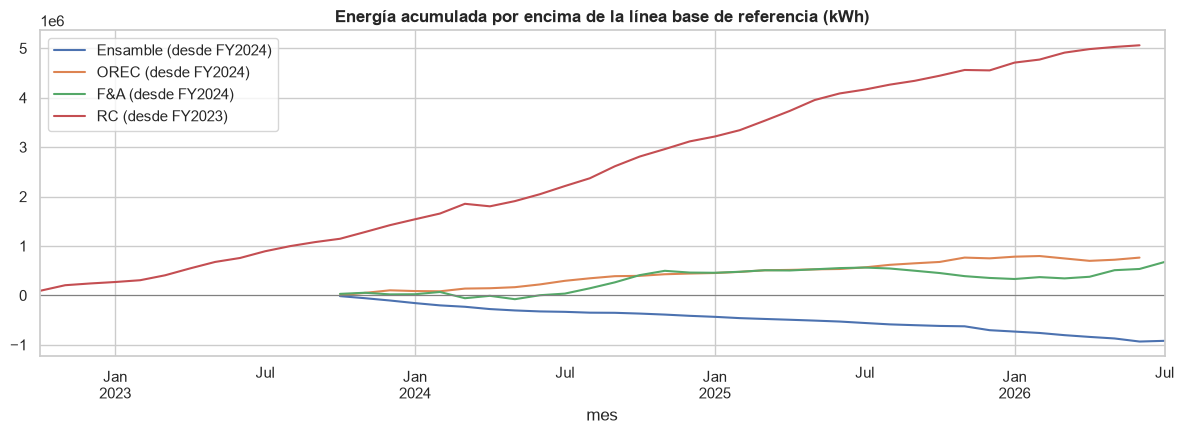

,desde,kwh_exceso_acumulado,COP_exceso_acumulado,kwh_exceso_FY2026,COP_exceso_FY2026,meses_FY2026
area,,,,,,
Ensamble,FY2024,"-920,352.22","-465,337,949.24","-316,714.77","-172,273,305.29",10
OREC,FY2024,"763,867.77","376,703,645.04","115,395.89","61,042,269.94",9
F&A,FY2024,"674,862.24","328,219,902.85","176,462.66","96,471,669.75",10
RC,FY2023,"5,061,098.52","2,476,955,888.46","719,321.69","390,241,520.20",9


In [26]:
# The tariff is the same for the whole plant: RC, which has no cost column,
# takes the month's plant tariff
plant_tariff = panel[panel["area"].isin(AREAS)].groupby("mes")["costo_unit"].mean()
fig, axis = plt.subplots(figsize=(12, 4.5))
cusum_rows = []
for area in DECOMPOSED:
    frame = series[area].copy()
    fit, mean_days = baselines[area]
    frame["exceso_kwh"] = frame["kwh"] - baseline_predict(fit, mean_days, frame)
    post = after_of(area, frame).copy()
    tariff = post["costo_unit"].fillna(plant_tariff.reindex(post.index)).bfill()
    post["exceso_cop"] = post["exceso_kwh"] * tariff
    post["exceso_kwh"].cumsum().plot(ax=axis, label=f"{area} (desde FY{REFERENCE[area][1] + 1})")
    cusum_rows.append(
        {
            "area": area,
            "desde": rotulo_fiscal(REFERENCE[area][1] + 1),
            "kwh_exceso_acumulado": post["exceso_kwh"].sum(),
            "COP_exceso_acumulado": post["exceso_cop"].sum(),
            "kwh_exceso_FY2026": post.loc[post["fy"] == CURRENT_FY, "exceso_kwh"].sum(),
            "COP_exceso_FY2026": post.loc[post["fy"] == CURRENT_FY, "exceso_cop"].sum(),
            "meses_FY2026": int((post["fy"] == CURRENT_FY).sum()),
        }
    )
axis.axhline(0, color="grey", lw=0.8)
axis.set_title("Energía acumulada por encima de la línea base de referencia (kWh)")
axis.legend()
plt.tight_layout()
plt.show()
cusum_table = pd.DataFrame(cusum_rows).set_index("area")
display(cusum_table)

### 5.2 Escenarios para FY2027

Con la línea base del régimen actual (últimos 24 meses) se calcula el kWh/EQ esperado en un mes típico de 30 días para tres volúmenes: los percentiles 25, 50 y 75 de los EQ mensuales de FY2026, con su intervalo de predicción del 90 %.

In [27]:
scenario_rows = []
for area in AREAS:
    frame = series[area]
    recent = frame[frame.index >= frame.index.max() - pd.DateOffset(months=23)]
    fit, mean_days = baseline_fit(recent)
    plain = sm.OLS(recent["kwh"], fit.model.exog).fit()
    eq_fy26 = frame.loc[frame["fy"] == CURRENT_FY, "eq"]
    for label, quantile in [("P25", 0.25), ("P50", 0.50), ("P75", 0.75)]:
        volume = eq_fy26.quantile(quantile)
        design = pd.DataFrame({"const": [1.0], "eq": [volume], "dias_c": [30 - mean_days]})
        forecast = plain.get_prediction(design).summary_frame(alpha=0.10)
        scenario_rows.append(
            {
                "area": area,
                "escenario": label,
                "EQ_mes": volume,
                "kwh_mes": forecast["mean"].iloc[0],
                "kwh_eq": forecast["mean"].iloc[0] / volume,
                "kwh_eq_ic90_inf": forecast["obs_ci_lower"].iloc[0] / volume,
                "kwh_eq_ic90_sup": forecast["obs_ci_upper"].iloc[0] / volume,
                "presupuesto_FY2026": frame["presupuesto"].dropna().median(),
            }
        )
scenarios = pd.DataFrame(scenario_rows).set_index(["area", "escenario"])
display(scenarios)

EQ_mes      kwh_mes  kwh_eq  kwh_eq_ic90_inf  kwh_eq_ic90_sup  presupuesto_FY2026
area     escenario                                                                                     
Ensamble P25       64,652.91   215,770.53    3.34             2.85             3.82                2.01
         P50       76,166.33   224,980.66    2.95             2.55             3.36                2.01
         P75       81,390.09   229,159.39    2.82             2.44             3.19                2.01
OREC     P25       52,322.01   366,217.01    7.00             5.94             8.06                5.86
         P50       68,626.84   444,970.73    6.48             5.70             7.27                5.86
         P75       73,321.33   467,645.51    6.38             5.65             7.11                5.86
F&A      P25       44,097.15   842,247.25   19.10            16.37            21.83               18.33
         P50       52,732.44 1,005,243.58   19.06            16.87            21.26               18.33
         P75       55,152.44 1,050,922.49   19.05            16.97            21.14               18.33

**Explicación técnica.** Energía acumulada fuera de la línea base de referencia, ya descontado el volumen:

| Área | Desde | kWh acumulados | COP acumulados | kWh en FY2026 | COP en FY2026 |
|---|---|---|---|---|---|
| RC | FY2023 | +5,061,099 | +2,477 millones | +719,322 (9 meses) | +390 millones |
| OREC | FY2024 | +763,868 | +377 millones | +115,396 (9 meses) | |
| F&A | FY2024 | +674,862 | +328 millones | +176,463 | no significativo (sección 3) |
| Ensamble | FY2024 | −920,352 | −465 millones | −316,715 | gasta menos de lo esperado para su volumen |

En los escenarios de FY2027, con el régimen actual, el kWh/EQ esperado con el volumen mediano de FY2026 es 2.95 en Ensamble (IC90 [2.55, 3.36]), 6.48 en OREC ([5.70, 7.27]) y 19.06 en F&A ([16.87, 21.26]). Los presupuestos de OREC (5.86) y F&A (18.33) caen dentro de sus intervalos, aunque en el extremo favorable; el de Ensamble (2.01) queda muy por debajo del suyo.

**Lectura de negocio.** El sobreconsumo que no explica el volumen se concentra en **RC: unos 2,500 millones de COP desde FY2023**, seis veces lo de OREC. Es donde una intervención de eficiencia tiene más retorno. Si FY2027 repite los volúmenes de FY2026, Ensamble volverá a quedar lejos de su presupuesto aunque opere exactamente igual de bien, y OREC y F&A solo lo alcanzarían en un mes favorable: hay que rehacer esas metas con la curva de volumen.

## 6. Conclusiones

**Resultados principales.**

| # | Hallazgo | Evidencia | Qué significa para la planta |
|---|---|---|---|
| 1 | El kWh/EQ de **Ensamble** sube por volumen, no por ineficiencia | Efecto volumen +1.13 contra desempeño −0.43 kWh/EQ en FY2026; robusto a la referencia | Está subutilizado: gasta unos 220 MWh/mes fijos. Producir más, o apagar cargas fijas (Línea 3), es la palanca |
| 2 | **OREC** pierde eficiencia desde sep-2023 | Quiebre sep-2023; desempeño +0.20 a +0.30 kWh/EQ cada año, residuo +23,148 kWh/mes (p < 0.001) | Más 377 millones de COP desde FY2024; revisar qué cambió al cerrar FY2023 |
| 3 | **RC** es el mayor problema de eficiencia | kWh/t de 131 a 225 (+71 %); desempeño +54 kWh/t en FY2026; quiebre oct-2022 | Más 5.1 GWh y unos 2,500 millones de COP desde FY2023 |
| 4 | En RC suben **a la vez** electricidad y gas por tonelada | Spearman 0.73 entre kWh/t y m³/t | Causa de proceso (rendimiento del horno, ley de la chatarra, arranques), no un equipo eléctrico |
| 5 | **F&A** está estable | Sin quiebre (p = 0.72), efectos no significativos | Su kWh/EQ solo sigue al volumen; su costo sube por tarifa (95 % del aumento) |
| 6 | La mezcla de producto no explica el aumento | Ningún efecto significativo por permutación, mensual ni diario | Los factores de la ecuación de EQ ya ponderan bien camión, peso y pasta |
| 7 | La cadena es de arrastre | OREC anticipa a RC (Granger p < 0.01), no al revés | Las toneladas bajas de RC son menos demanda, no falta de plomo |
| 8 | El presupuesto de FY2026 no era alcanzable | Ensamble necesitaba EQ del percentil 99 de su historia; el marginal de F&A (18.88) supera la meta (18.33) | Fijar metas como curva de volumen, no como número fijo |
| 9 | La energía se predice bien si se conoce el volumen | MASE 0.47 a 0.68 (WAPE 4 % a 5 %); diario F&A, WAPE 12 % | Línea base lista para alertas mensuales y diarias (detalle en la sección 7) |
| 10 | Los EQ de F&A del libro no son los de la ecuación | 7 % más que la base de datos; kWh/EQ 20.83 en vez de 19.33 | Acordar la fuente antes de evaluar metas |

**Siguientes pasos para la planta.**

* Preguntar a RC qué cambió en oct-2022: tipo de chatarra, rendimiento por carga, número de arranques de horno.
* Preguntar a OREC qué cambió en sep-2023 (equipos, Cinta y Empaste Expanded, que `OREC_analysis` ya señaló).
* Asentar el plomo refinado el día en que se produce, para medir RC a diario.
* Instalar o identificar el medidor del tercio de la energía de RC que los siete medidores no ven.
* Rehacer los presupuestos de kWh/EQ como curvas de volumen y usar la línea base de la sección 5 como monitoreo mensual.

## 7. El hallazgo 9 en detalle: la línea base de energía

El hallazgo 9 de las conclusiones dice que **la energía se predice bien si se conoce el volumen**. En palabras simples: si se sabe cuántos EQ va a producir un área en el mes y cuántos días tiene el mes, se puede anticipar su consumo de energía con un error típico de alrededor del 5 %, cuando la regla «igual que el mes pasado» se equivoca entre 8 % y 10 %.

Esta sección escribe ese modelo como un `Pipeline` de scikit-learn, dice exactamente qué entra y qué sale, lo vuelve a evaluar y lo reporta en términos de planta.

**Especificación.**

| | Mensual (Ensamble, OREC, F&A) | Diario (F&A) |
|---|---|---|
| **Objetivo (target)** | `kwh`: energía del mes del área, fila total, columna `KWH` de `Base_de_datos.xlsx` | `kwh`: energía del día de los rectificadores (SCADA de F&A) |
| **Variables (features)** | `eq`: EQ del mes (`Produccion (Equivalente)` del libro)<br>`dias`: días calendario del mes, centrados en su promedio de entrenamiento | `eq`: EQ de F&A del día (base de datos)<br>`domingo`: 1 si es domingo<br>`sin_eq`: 1 si el día no registró EQ |
| **Modelo** | `LinearRegression` (mínimos cuadrados) | `LinearRegression` |
| **Ventana de entrenamiento** | Últimos 36 meses en Ensamble y OREC; toda la historia en F&A | Todos los días anteriores |
| **Evaluación** | `TimeSeriesSplit(n_splits=24, test_size=1)`: 24 pronósticos a un mes | `TimeSeriesSplit(n_splits=30, test_size=1)`: 30 pronósticos a un día |

**Por qué esas ventanas.** La regla sale de la sección 2, no de los resultados de prueba: Ensamble (oct-2021) y OREC (sep-2023) tienen un quiebre estructural, así que solo se usa la relación reciente; F&A no tiene quiebre (p = 0.72) y usa toda su historia.

**Por qué no un split aleatorio.** Cada pliegue de `TimeSeriesSplit` entrena solo con el pasado y pronostica el periodo siguiente, como se usaría en la planta. Es la misma evaluación con origen móvil de la sección 5.

In [28]:
TARGET = "kwh"
FEATURES_MONTHLY = ["eq", "dias"]
FEATURES_DAILY = ["eq", "domingo", "sin_eq"]
TEST_MONTHS, TEST_DAYS = 24, 30
BREAK_WINDOW = 36  # months kept when the area has a structural break (section 2)
TRAIN_WINDOW: dict[str, int | None] = {"Ensamble": BREAK_WINDOW, "OREC": BREAK_WINDOW, "F&A": None}
MONTH_DAYS = 30  # the typical month of the worked example


def monthly_pipeline() -> Pipeline:
    """Energy of the month from its EQ and its calendar days (days centred on the training mean)."""
    variables = ColumnTransformer(
        [
            ("eq", "passthrough", ["eq"]),
            ("dias_centrados", StandardScaler(with_std=False), ["dias"]),
        ],
        verbose_feature_names_out=False,
    )
    return Pipeline([("variables", variables), ("regresion", LinearRegression())])


def daily_pipeline() -> Pipeline:
    """Energy of the day from its EQ and two 0/1 indicators: Sunday and a day without EQ."""
    variables = ColumnTransformer(
        [("eq_e_indicadores", "passthrough", FEATURES_DAILY)],
        verbose_feature_names_out=False,
    )
    return Pipeline([("variables", variables), ("regresion", LinearRegression())])


print("Pipeline mensual (una por área):")
display(monthly_pipeline())
print("Pipeline diario (F&A):")
display(daily_pipeline())

Pipeline mensual (una por área):


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('variables', ...), ('regresion', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('eq', ...), ('dias_centrados', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{f

Pipeline diario (F&A):


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('variables', ...), ('regresion', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('eq_e_indicadores', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name

In [29]:
def pipeline_backtest(
    frame: pd.DataFrame,
    features: list[str],
    pipeline_factory: Callable[[], Pipeline],
    n_splits: int,
    max_train_size: int | None,
) -> tuple[dict[str, pd.DataFrame], pd.DataFrame]:
    """One-step-ahead forecasts of a fresh pipeline per fold, beside the naive forecast.

    Also returns, per fold, the fit of its pipeline on its own training window
    (R2, MAE and WAPE in sample).
    """
    splitter = TimeSeriesSplit(n_splits=n_splits, test_size=1, max_train_size=max_train_size)
    rows, train_rows = [], []
    for train_index, test_index in splitter.split(frame):
        train, test = frame.iloc[train_index], frame.iloc[test_index]
        model = pipeline_factory().fit(train[features], train[TARGET])
        in_sample = (train[TARGET] - model.predict(train[features])).abs()
        train_rows.append(
            {
                "t": test.index[0],
                "R2": model.score(train[features], train[TARGET]),
                "MAE": in_sample.mean(),
                "WAPE_%": 100 * in_sample.sum() / train[TARGET].abs().sum(),
            }
        )
        rows.append(
            {
                "t": test.index[0],
                "Pipeline": model.predict(test[features])[0],
                "Ingenuo": train[TARGET].iloc[-1],
            }
        )
    out = pd.DataFrame(rows).set_index("t")
    forecasts = {name: out[[name]].rename(columns={name: "pred"}) for name in out.columns}
    return forecasts, pd.DataFrame(train_rows).set_index("t")


# name, data, features, pipeline, periods tested, training window,
# and the MAE of the same model in section 5
CASES = [
    (
        area,
        series[area][[TARGET, *FEATURES_MONTHLY]].dropna(),
        FEATURES_MONTHLY,
        monthly_pipeline,
        TEST_MONTHS,
        TRAIN_WINDOW[area],
        results_a[area].loc[
            "OLS EQ + días (ventana creciente)"
            if TRAIN_WINDOW[area] is None
            else f"OLS EQ + días (últimos {BREAK_WINDOW} meses)",
            "MAE",
        ],
    )
    for area in AREAS
]
CASES.append(
    (
        "F&A diario",
        fa_series,
        FEATURES_DAILY,
        daily_pipeline,
        TEST_DAYS,
        None,
        results_c.loc["OLS EQ + domingo + sin EQ", "MAE"],
    )
)

SPEC = "especificación"
TRAINING = "entrenamiento"
VALIDATION = "validación cruzada temporal (fuera de muestra)"
backtests, train_fits, summary_rows = {}, {}, []
for name, frame, features, factory, n_test, window, mae_section5 in CASES:
    forecasts, train_fit = pipeline_backtest(frame, features, factory, n_test, window)
    actual = frame[TARGET].iloc[-n_test:]
    scores = evaluate(forecasts, actual)
    # the pipeline is the same model as section 5: same out-of-sample error
    assert np.isclose(scores.loc["Pipeline", "MAE"], mae_section5), name
    _, dm_p = diebold_mariano(
        forecasts["Pipeline"]["pred"] - actual, forecasts["Ingenuo"]["pred"] - actual
    )
    backtests[name] = (forecasts, actual)
    train_fits[name] = train_fit
    unit = "días" if name == "F&A diario" else "meses"
    summary_rows.append(
        {
            (SPEC, "caso"): name,
            (SPEC, "objetivo"): TARGET,
            (SPEC, "variables"): " + ".join(features),
            (SPEC, "ventana"): "toda la historia" if window is None else f"últimos {window} {unit}",
            (SPEC, "pliegues"): f"{n_test} {unit}",
            (TRAINING, "R2_promedio_pliegues"): train_fit["R2"].mean(),
            (TRAINING, "WAPE_%_promedio_pliegues"): train_fit["WAPE_%"].mean(),
            (VALIDATION, "R2"): r2_score(actual, forecasts["Pipeline"]["pred"]),
            (VALIDATION, "MAE_kWh"): scores.loc["Pipeline", "MAE"],
            (VALIDATION, "WAPE_%"): scores.loc["Pipeline", "WAPE_%"],
            (VALIDATION, "MASE"): scores.loc["Pipeline", "MASE"],
            (VALIDATION, "WAPE_ingenuo_%"): scores.loc["Ingenuo", "WAPE_%"],
            (VALIDATION, "DM_p_vs_ingenuo"): dm_p,
        }
    )

pipeline_summary = pd.DataFrame(summary_rows).set_index((SPEC, "caso"))
pipeline_summary.columns = pd.MultiIndex.from_tuples(pipeline_summary.columns)
pipeline_summary.index.name = "caso"
print("El pipeline reproduce el error fuera de muestra de la sección 5 en los cuatro casos.")
print("Entrenamiento: R2 y WAPE de cada pliegue sobre su propia ventana, promediados.")
print("Validación: los pronósticos a un periodo de TimeSeriesSplit, cada uno sin ver su dato.")
display(pipeline_summary)

El pipeline reproduce el error fuera de muestra de la sección 5 en los cuatro casos.
Entrenamiento: R2 y WAPE de cada pliegue sobre su propia ventana, promediados.
Validación: los pronósticos a un periodo de TimeSeriesSplit, cada uno sin ver su dato.


especificación                                                           entrenamiento                          validación cruzada temporal (fuera de muestra)                        \
                 objetivo              variables           ventana  pliegues R2_promedio_pliegues WAPE_%_promedio_pliegues                                             R2   MAE_kWh WAPE_% MASE   
caso                                                                                                                                                                                              
Ensamble              kwh              eq + dias  últimos 36 meses  24 meses                 0.16                     6.55                                           0.38 13,396.07   5.34 0.68   
OREC                  kwh              eq + dias  últimos 36 meses  24 meses                 0.75                     3.82                                           0.91 27,085.04   4.89 0.48   
F&A                   kwh              eq + dias  toda la historia  24 meses                 0.83                     5.08                                           0.83 50,704.35   4.72 0.55   
F&A diario            kwh  eq + domingo + sin_eq  toda la historia   30 días                 0.93                    13.22                                           0.90  4,433.46  12.28 0.28   

                                           
           WAPE_ingenuo_% DM_p_vs_ingenuo  
caso                                       
Ensamble             7.82            0.27  
OREC                10.21            0.03  
F&A                  8.63            0.07  
F&A diario          44.25            0.00

In [30]:
def signed(value: float, unit: str, digits: int = 0) -> str:
    """A term of an equation with its own sign, e.g. "+ 4.79 * EQ" or "- 8,335 * domingo"."""
    return f"{'+' if value >= 0 else '-'} {abs(value):,.{digits}f} * {unit}"


monthly_rows, final_models = [], {}
for name, frame, features, factory, _n_test, window, _mae in CASES[:-1]:
    train = frame if window is None else frame.iloc[-window:]
    model = factory().fit(train[features], train[TARGET])
    final_models[name] = model
    regression = model.named_steps["regresion"]
    coef = pd.Series(regression.coef_, index=model.named_steps["variables"].get_feature_names_out())
    mean_days = model.named_steps["variables"].named_transformers_["dias_centrados"].mean_[0]
    fixed = regression.intercept_ + coef["dias"] * (MONTH_DAYS - mean_days)
    forecasts, actual = backtests[name]
    errors = forecasts["Pipeline"]["pred"] - actual
    eq_typical = series[name].loc[series[name]["fy"] == CURRENT_FY, "eq"].median()
    example = model.predict(pd.DataFrame({"eq": [eq_typical], "dias": [MONTH_DAYS]}))[0]
    monthly_rows.append(
        {
            "area": name,
            "entrenado_desde": f"{train.index.min():%Y-%m}",
            "entrenado_hasta": f"{train.index.max():%Y-%m}",
            "meses_entrenamiento": len(train),
            "kWh_fijos_mes_30_dias": fixed,
            "kWh_por_EQ": coef["eq"],
            "kWh_por_dia_adicional": coef["dias"],
            "R2_entrenamiento": model.score(train[features], train[TARGET]),
            "umbral_alerta_90_kWh": Z90 * errors.std(ddof=1),
            "EQ_mes_tipico_FY2026": eq_typical,
            "kWh_esperados_mes_tipico": example,
            "kWh_EQ_esperado_mes_tipico": example / eq_typical,
            "ecuacion": (
                f"kWh = {fixed:,.0f} {signed(coef['eq'], 'EQ', 2)} "
                f"{signed(coef['dias'], '(días - 30)')}"
            ),
        }
    )
monthly_models = pd.DataFrame(monthly_rows).set_index("area")
print("Modelo final mensual, ajustado con la ventana más reciente de cada área:")
display(monthly_models.drop(columns="ecuacion"))
for area, equation in monthly_models["ecuacion"].items():
    print(f"{area}: {equation}")

name, frame, features, factory, *_ = CASES[-1]
daily_model = factory().fit(frame[features], frame[TARGET])
final_models[name] = daily_model
coef = pd.Series(
    daily_model.named_steps["regresion"].coef_,
    index=daily_model.named_steps["variables"].get_feature_names_out(),
)
intercept = daily_model.named_steps["regresion"].intercept_
forecasts, actual = backtests[name]
errors = forecasts["Pipeline"]["pred"] - actual
eq_typical = frame.loc[(frame["eq"] > 0) & (frame["domingo"] == 0), "eq"].median()
typical_day = pd.DataFrame({"eq": [eq_typical], "domingo": [0.0], "sin_eq": [0.0]})
example = daily_model.predict(typical_day)[0]
daily_terms = pd.Series(
    {
        "kWh_base_dia_con_produccion": intercept,
        "kWh_por_EQ": coef["eq"],
        "cambio_kWh_domingo": coef["domingo"],
        "cambio_kWh_dia_sin_EQ": coef["sin_eq"],
        "R2_entrenamiento": daily_model.score(frame[features], frame[TARGET]),
        "umbral_alerta_90_kWh": Z90 * errors.std(ddof=1),
        "EQ_dia_tipico": eq_typical,
        "kWh_esperados_dia_tipico": example,
    },
    name="F&A diario",
)
print(f"Modelo final diario de F&A, {frame.index.min():%Y-%m-%d} a {frame.index.max():%Y-%m-%d}:")
display(daily_terms.to_frame())
print(
    f"F&A diario: kWh = {intercept:,.0f} {signed(coef['eq'], 'EQ', 2)} "
    f"{signed(coef['domingo'], 'domingo')} {signed(coef['sin_eq'], 'sin_EQ')}"
)

Modelo final mensual, ajustado con la ventana más reciente de cada área:


,entrenado_desde,entrenado_hasta,meses_entrenamiento,kWh_fijos_mes_30_dias,kWh_por_EQ,kWh_por_dia_adicional,R2_entrenamiento,umbral_alerta_90_kWh,EQ_mes_tipico_FY2026,kWh_esperados_mes_tipico,kWh_EQ_esperado_mes_tipico
area,,,,,,,,,,,
Ensamble,2023-08,2026-07,36,"171,050.78",0.69,"6,788.33",0.59,"36,724.89","76,166.33","223,955.53",2.94
OREC,2023-07,2026-06,36,"116,804.45",4.79,"6,239.45",0.93,"59,411.46","68,626.84","445,528.63",6.49
F&A,2019-10,2026-07,82,"115,647.94",16.78,"16,367.74",0.86,"108,646.41","52,732.44","1,000,409.13",18.97


Ensamble: kWh = 171,051 + 0.69 * EQ + 6,788 * (días - 30)
OREC: kWh = 116,804 + 4.79 * EQ + 6,239 * (días - 30)
F&A: kWh = 115,648 + 16.78 * EQ + 16,368 * (días - 30)
Modelo final diario de F&A, 2026-07-02 a 2026-09-30:


,F&A diario
kWh_base_dia_con_produccion,"10,828.71"
kWh_por_EQ,15.39
cambio_kWh_domingo,"-8,335.13"
cambio_kWh_dia_sin_EQ,"-1,533.12"
R2_entrenamiento,0.92
umbral_alerta_90_kWh,"9,225.88"
EQ_dia_tipico,"2,236.95"
kWh_esperados_dia_tipico,"45,246.15"


F&A diario: kWh = 10,829 + 15.39 * EQ - 8,335 * domingo - 1,533 * sin_EQ


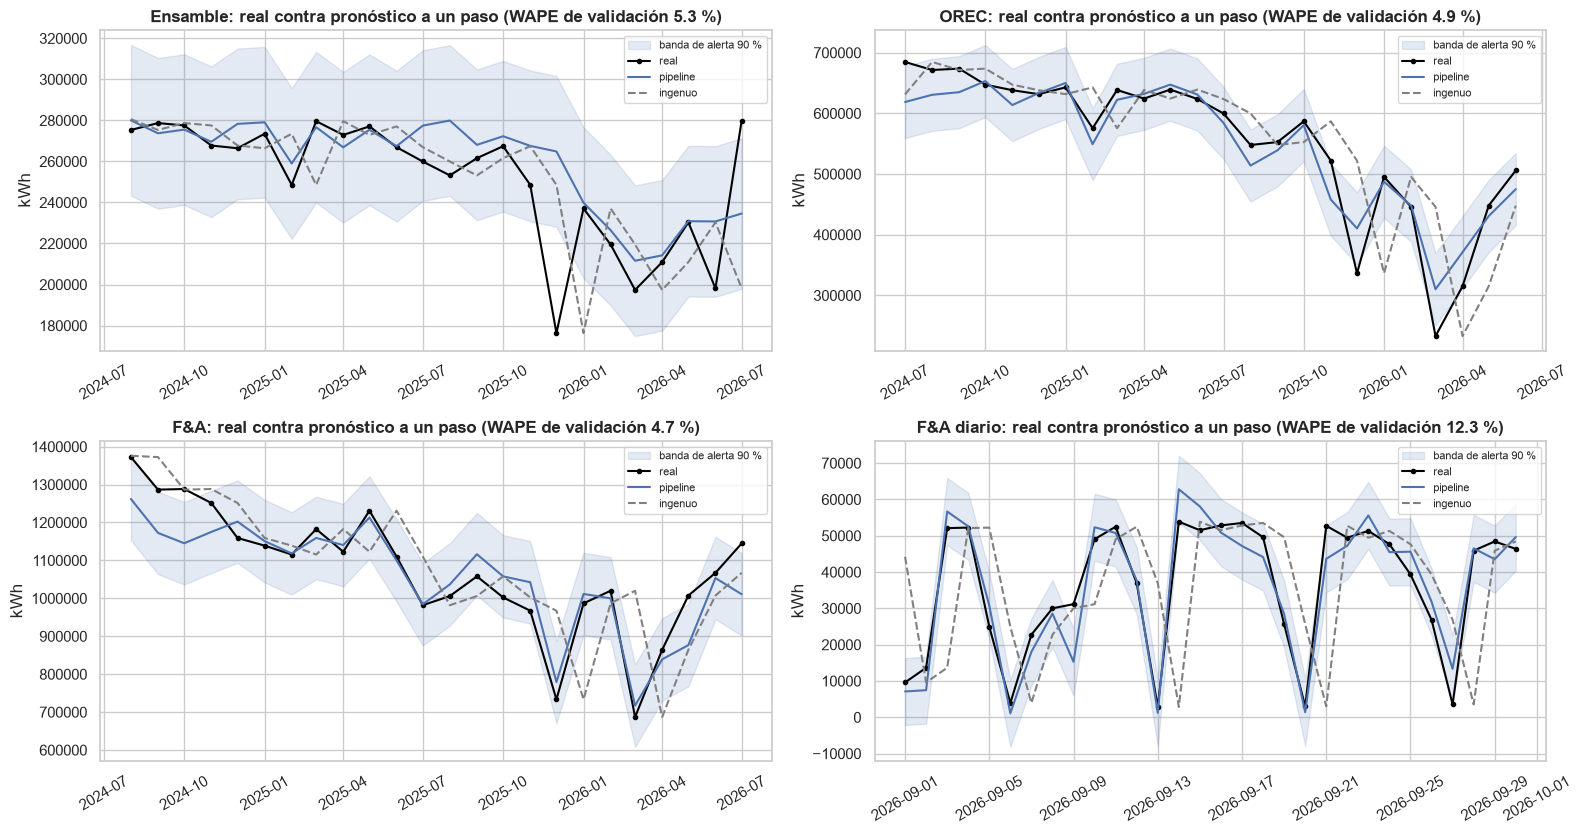

Periodos fuera de la banda de alerta del 90 % (real - esperado):


real_kWh  esperado_kWh  diferencia_kWh        alerta
caso       periodo                                                            
Ensamble   2025-12      176,309.00    264,864.15      -88,555.15  consumo bajo
           2026-07      279,900.00    234,602.46       45,297.54  sobreconsumo
OREC       2024-07      684,713.00    618,702.79       66,010.21  sobreconsumo
           2025-11      522,072.00    457,873.19       64,198.81  sobreconsumo
           2025-12      336,474.00    410,471.63      -73,997.63  consumo bajo
           2026-03      232,918.00    310,136.70      -77,218.70  consumo bajo
F&A        2024-08    1,372,420.00  1,261,882.19      110,537.81  sobreconsumo
           2024-09    1,286,607.00  1,172,520.52      114,086.48  sobreconsumo
           2024-10    1,288,209.00  1,145,206.19      143,002.81  sobreconsumo
           2026-05    1,007,250.00    876,641.03      130,608.97  sobreconsumo
           2026-07    1,144,675.00  1,010,743.34      133,931.66  sobreconsumo
F&A diario 2026-09-09    31,159.02     15,263.59       15,895.44  sobreconsumo
           2026-09-27     3,524.44     13,331.55       -9,807.11  consumo bajo

In [31]:
fig, axes = plt.subplots(2, 2, figsize=(16, 8.5))
thresholds = monthly_models["umbral_alerta_90_kWh"].to_dict()
thresholds["F&A diario"] = daily_terms["umbral_alerta_90_kWh"]
for axis, (name, (forecasts, actual)) in zip(axes.flat, backtests.items(), strict=True):
    predicted = forecasts["Pipeline"]["pred"]
    band = thresholds[name]
    axis.fill_between(
        predicted.index,
        predicted - band,
        predicted + band,
        color="#4C72B0",
        alpha=0.15,
        label="banda de alerta 90 %",
    )
    axis.plot(actual.index, actual, color="black", marker="o", ms=3, label="real")
    axis.plot(predicted.index, predicted, color="#4C72B0", label="pipeline")
    naive = forecasts["Ingenuo"]["pred"]
    axis.plot(naive.index, naive, color="grey", ls="--", label="ingenuo")
    wape = pipeline_summary.loc[name, (VALIDATION, "WAPE_%")]
    axis.set_title(f"{name}: real contra pronóstico a un paso (WAPE de validación {wape:.1f} %)")
    axis.set_ylabel("kWh")
    axis.ticklabel_format(axis="y", style="plain")
    axis.tick_params(axis="x", labelrotation=30)
    axis.legend(fontsize=8)
plt.tight_layout()
plt.show()

# Periods the alert band would have flagged: error beyond the 90 % threshold
alert_rows = []
for name, (forecasts, actual) in backtests.items():
    error = actual - forecasts["Pipeline"]["pred"]
    for stamp in error[error.abs() > thresholds[name]].index:
        alert_rows.append(
            {
                "caso": name,
                "periodo": f"{stamp:%Y-%m-%d}" if name == "F&A diario" else f"{stamp:%Y-%m}",
                "real_kWh": actual[stamp],
                "esperado_kWh": forecasts["Pipeline"]["pred"][stamp],
                "diferencia_kWh": error[stamp],
                "alerta": "sobreconsumo" if error[stamp] > 0 else "consumo bajo",
            }
        )
alerts = pd.DataFrame(alert_rows).set_index(["caso", "periodo"])
print("Periodos fuera de la banda de alerta del 90 % (real - esperado):")
display(alerts)

**Explicación técnica.**

* **El modelo.** Cada `Pipeline` tiene dos pasos. `variables` (un `ColumnTransformer`) deja pasar `eq` tal cual y centra `dias` en su promedio de entrenamiento. `regresion` es un `LinearRegression`. El objetivo es siempre `kwh`. En cada pliegue de `TimeSeriesSplit` se crea un pipeline nuevo y se ajusta solo con el pasado, así que el centrado de los días tampoco ve el futuro.
* **Es el mismo modelo de la sección 5.** El MAE fuera de muestra del pipeline coincide con el de «OLS EQ + días» y «OLS EQ + domingo + sin EQ» en los cuatro casos, y la celda lo comprueba con `assert`.
* **Métricas, separadas por origen.**
  * **Entrenamiento:** el R² de cada pliegue sobre su propia ventana de entrenamiento, promediado sobre los pliegues.
  * **Validación:** todo lo demás. Sale de la **validación cruzada temporal** (`TimeSeriesSplit`, un periodo adelante), es decir, de pronósticos que no vieron su propio dato: 24 meses en los modelos mensuales y 30 días en el diario. No hay un conjunto de prueba aparte.

  | Caso | R² entrenamiento (promedio de pliegues) | R² validación | WAPE validación | MASE validación | WAPE validación del ingenuo | Diebold-Mariano p (validación) |
  |---|---|---|---|---|---|---|
  | Ensamble | 0.16 | 0.38 | 5.34 % | 0.68 | 7.82 % | 0.27 |
  | OREC | 0.75 | 0.91 | 4.89 % | 0.48 | 10.21 % | 0.03 |
  | F&A | 0.83 | 0.83 | 4.72 % | 0.55 | 8.63 % | 0.07 |
  | F&A diario | 0.93 | 0.90 | 12.28 % | 0.28 | 44.25 % | < 0.01 |

* **Cómo leer los R².**
  * **No hay sobreajuste:** el R² de validación no es menor que el de entrenamiento, salvo una diferencia mínima en el diario (0.93 contra 0.90).
  * **En Ensamble y OREC el R² de validación es mayor.** El R² mide qué parte de la *variación* se explica, y los meses de validación (ago-2024 a jul-2026) incluyen la caída de volumen de FY2026, mucho más variación que las ventanas de entrenamiento.
  * **El R² bajo de Ensamble en entrenamiento (0.16) no es un mal pronóstico.** En esas ventanas casi toda su energía es carga fija y apenas varía, así que queda poca variación por explicar, aunque el error sea pequeño (WAPE de validación 5.34 %). Para pronosticar importan el WAPE y el MASE.

* **Errores AR(1).** Agregarlos, como en la regresión de la sección 5, mejora poco: el MASE de validación pasa de 0.48 a 0.47 en OREC y de 0.55 a 0.49 en F&A. scikit-learn no tiene ese término, y el pipeline lineal es el que se puede poner en operación tal cual.
* **El modelo final** se ajusta con la ventana más reciente de cada área. Su R² es de entrenamiento, sobre esa ventana:
  * **Ensamble:** kWh = 171,051 + 0.69 · EQ + 6,788 · (días − 30), R² 0.59;
  * **OREC:** kWh = 116,804 + 4.79 · EQ + 6,239 · (días − 30), R² 0.93;
  * **F&A:** kWh = 115,648 + 16.78 · EQ + 16,368 · (días − 30), R² 0.86;
  * **F&A diario:** kWh = 10,829 + 15.39 · EQ − 8,335 · domingo − 1,533 · sin EQ, R² 0.92.
* **Banda de alerta.** Es 1.645 desviaciones estándar de los errores de validación: 36,725 kWh en Ensamble, 59,411 en OREC, 108,646 en F&A y 9,226 kWh por día en F&A diario. Marcó 2 de 24 meses en Ensamble, 4 en OREC y 5 en F&A, y 2 de 30 días en el diario. En F&A los cinco son de sobreconsumo, lo que sugiere que su relación se desplazó un poco hacia arriba; por eso esa banda se debe revisar con más datos.

**Lectura de negocio.**

* **Con el plan de producción se conoce la energía antes de que empiece el mes.** Basta saber cuántos EQ se van a producir y cuántos días tiene el mes. El error típico en validación es de alrededor del 5 %, frente a 8 % a 10 % de suponer «igual que el mes pasado».
* **Cada área se resume en dos números: lo que gasta aunque no produzca y lo que suma cada EQ.**
  * **Ensamble:** 171,051 kWh fijos por mes de 30 días y solo 0.69 kWh por EQ adicional. En un mes típico de FY2026 (76,166 EQ), 171,051 de los 223,956 kWh esperados son fijos: es el área donde el volumen pesa menos y la carga fija más (hallazgo 1).
  * **OREC:** 116,804 kWh fijos y 4.79 kWh por EQ.
  * **F&A:** 115,648 kWh fijos y 16.78 kWh por EQ. Su energía la manda el volumen.
  * **F&A diario:** un domingo consume 8,335 kWh menos que un día normal con la misma producción.
* **Cómo se lee una alerta.** Al cerrar el mes se compara el consumo real con el esperado para lo que se produjo. Si la diferencia supera la banda, hay algo que revisar:
  * **arriba,** energía de más (por ejemplo Ensamble en jul-2026, +45,298 kWh);
  * **abajo,** una parada o un dato incompleto (por ejemplo Ensamble en dic-2025, −88,555 kWh).
* **El modelo juzga la energía *para el volumen producido*.** Así separa el desperdicio del bajo volumen: un mes con pocos EQ y kWh/EQ alto no genera alerta si el consumo es el esperado para ese volumen.

### 7.1 Sobreajuste, significancia de las variables y residuales

Tres comprobaciones del modelo de la sección 7.

* **Entrenamiento contra validación.** En cada pliegue de `TimeSeriesSplit` se mide el ajuste del pipeline sobre su propia ventana de entrenamiento (R² y WAPE dentro de muestra) y se promedia sobre los pliegues. La validación son los pronósticos fuera de muestra de esos mismos pliegues. Un modelo sobreajustado se ve mucho mejor en entrenamiento que en validación.
* **Valores p de las variables.** scikit-learn no calcula errores estándar. Por eso el modelo final de cada caso se vuelve a ajustar con `statsmodels` sobre exactamente las columnas que produce el paso `variables` del pipeline, y la celda comprueba que los coeficientes coinciden. Los valores p usan errores **Newey-West (HAC)**, robustos a autocorrelación y heterocedasticidad: 3 rezagos en los modelos mensuales y 7 en el diario. Se muestran también los de MCO clásico.
* **Residuales.** Para cada modelo se grafican tres cosas:
  * residual contra valor ajustado, para ver la forma funcional y la varianza;
  * residuales en el tiempo, de entrenamiento y de validación;
  * un Q-Q normal.

  Se acompañan de las pruebas de `DiagnosticoOLS`: Jarque-Bera, Breusch-Pagan, RESET y Durbin-Watson, más Ljung-Box.

Entrenamiento (promedio de los pliegues) contra validación cruzada temporal:


,R2_entrenamiento,R2_validacion,WAPE_%_entrenamiento,WAPE_%_validacion,brecha_WAPE_pp,WAPE_validacion_sobre_entrenamiento
caso,,,,,,
Ensamble,0.16,0.38,6.55,5.34,-1.21,0.82
OREC,0.75,0.91,3.82,4.89,1.08,1.28
F&A,0.83,0.83,5.08,4.72,-0.36,0.93
F&A diario,0.93,0.90,13.22,12.28,-0.94,0.93


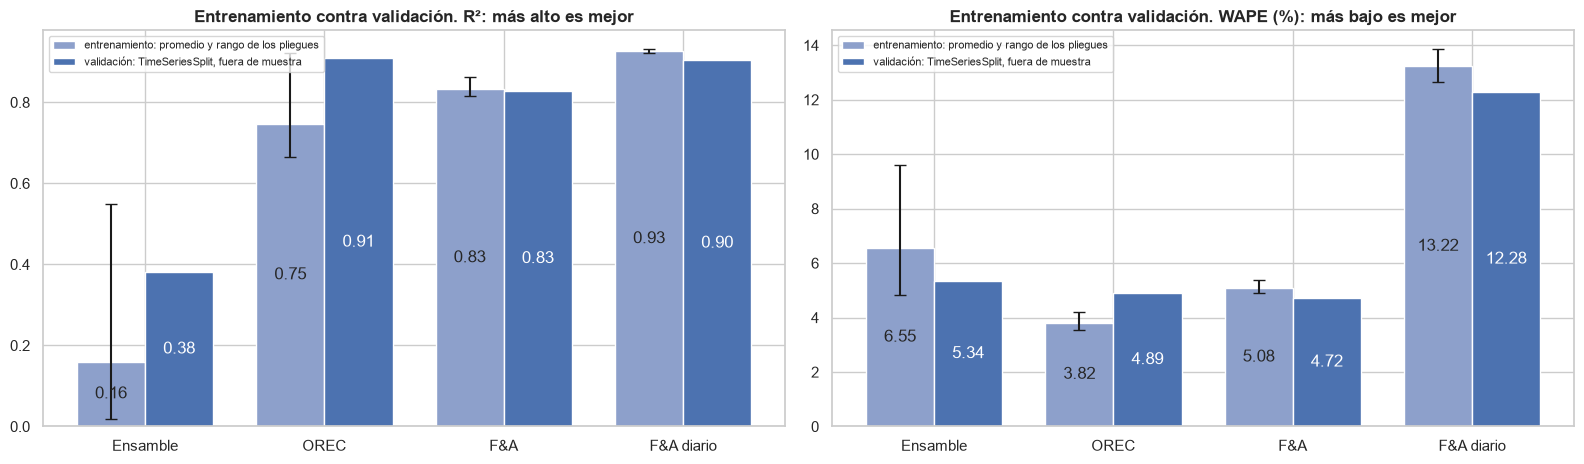

In [32]:
comparison = pd.DataFrame(
    {
        "R2_entrenamiento": pipeline_summary[(TRAINING, "R2_promedio_pliegues")],
        "R2_validacion": pipeline_summary[(VALIDATION, "R2")],
        "WAPE_%_entrenamiento": pipeline_summary[(TRAINING, "WAPE_%_promedio_pliegues")],
        "WAPE_%_validacion": pipeline_summary[(VALIDATION, "WAPE_%")],
    }
)
comparison["brecha_WAPE_pp"] = comparison["WAPE_%_validacion"] - comparison["WAPE_%_entrenamiento"]
comparison["WAPE_validacion_sobre_entrenamiento"] = (
    comparison["WAPE_%_validacion"] / comparison["WAPE_%_entrenamiento"]
)
print("Entrenamiento (promedio de los pliegues) contra validación cruzada temporal:")
display(comparison)

BAR = 0.38
PANELS = [("R2", "R²: más alto es mejor"), ("WAPE_%", "WAPE (%): más bajo es mejor")]
positions = np.arange(len(comparison))
fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
for axis, (metric, title) in zip(axes, PANELS, strict=True):
    folds = [train_fits[name][metric] for name in comparison.index]
    train_mean = comparison[f"{metric}_entrenamiento"].to_numpy()
    low = np.array([values.min() for values in folds])
    high = np.array([values.max() for values in folds])
    train_bars = axis.bar(
        positions - BAR / 2,
        train_mean,
        BAR,
        yerr=[train_mean - low, high - train_mean],
        capsize=4,
        color="#8DA0CB",
        label="entrenamiento: promedio y rango de los pliegues",
    )
    validation_bars = axis.bar(
        positions + BAR / 2,
        comparison[f"{metric}_validacion"],
        BAR,
        color="#4C72B0",
        label="validación: TimeSeriesSplit, fuera de muestra",
    )
    axis.bar_label(train_bars, fmt="%.2f", label_type="center")
    axis.bar_label(validation_bars, fmt="%.2f", label_type="center", color="white")
    axis.set_xticks(positions, comparison.index)
    axis.set_title(f"Entrenamiento contra validación. {title}")
    axis.legend(fontsize=8, loc="upper left")
plt.tight_layout()
plt.show()

In [33]:
MONTHLY_HAC_LAGS = 3  # as in sections 3 and 5
HAC_LAGS = {"F&A diario": WEEK}
TERM_NAMES = {"const": "intercepto", "dias": "dias (centrado)"}


def format_p(p: float) -> str:
    """A p-value as text: three decimals, or < 0.001."""
    return "< 0.001" if p < 0.001 else f"{p:.3f}"  # noqa: PLR2004


coefficient_rows, diagnostic_rows, final_fits = [], [], {}
for name, frame, features, _factory, _n_test, window, _mae in CASES:
    train = frame if window is None else frame.iloc[-window:]
    model = final_models[name]
    variables = model.named_steps["variables"]
    design = sm.add_constant(
        pd.DataFrame(
            variables.transform(train[features]),
            index=train.index,
            columns=variables.get_feature_names_out(),
        )
    )
    lags = HAC_LAGS.get(name, MONTHLY_HAC_LAGS)
    plain = sm.OLS(train[TARGET], design).fit()
    robust = sm.OLS(train[TARGET], design).fit(cov_type="HAC", cov_kwds={"maxlags": lags})
    regression = model.named_steps["regresion"]
    # the same coefficients as the scikit-learn pipeline
    assert np.allclose(plain.params.to_numpy(), [regression.intercept_, *regression.coef_]), name
    final_fits[name] = plain
    interval = robust.conf_int()
    for term in plain.params.index:
        coefficient_rows.append(
            {
                "caso": name,
                "variable": TERM_NAMES.get(term, term),
                "coef": plain.params[term],
                "ee_HAC": robust.bse[term],
                "t_HAC": robust.tvalues[term],
                "p_HAC": format_p(robust.pvalues[term]),
                "p_MCO_clasico": format_p(plain.pvalues[term]),
                "ic95_inf": interval.loc[term, 0],
                "ic95_sup": interval.loc[term, 1],
                "significativa_5%": "sí" if robust.pvalues[term] < ALPHA else "no",
            }
        )
    tests = DiagnosticoOLS(plain).pruebas_hipotesis(mostrar=False).set_index("prueba")
    diagnostic_rows.append(
        {
            "caso": name,
            "n_entrenamiento": int(plain.nobs),
            "rezagos_HAC": lags,
            "R2_entrenamiento": plain.rsquared,
            "F_global_p": format_p(plain.f_pvalue),
            "Jarque_Bera_p": format_p(tests.loc["Jarque-Bera", "p_valor"]),
            "Breusch_Pagan_p": format_p(tests.loc["Breusch-Pagan", "p_valor"]),
            "RESET_p": format_p(tests.loc["Ramsey RESET", "p_valor"]),
            "Durbin_Watson": tests.loc["Durbin-Watson", "estadistico"],
            "Ljung_Box_6_p": format_p(acorr_ljungbox(plain.resid, lags=[6])["lb_pvalue"].iloc[0]),
        }
    )

feature_pvalues = pd.DataFrame(coefficient_rows).set_index(["caso", "variable"])
print("Coeficientes del modelo final y valores p de cada variable (HAC Newey-West y MCO clásico):")
display(feature_pvalues)
residual_tests = pd.DataFrame(diagnostic_rows).set_index("caso")
print("Pruebas sobre los residuales de entrenamiento del modelo final (H0 = supuesto cumplido):")
display(residual_tests)

Coeficientes del modelo final y valores p de cada variable (HAC Newey-West y MCO clásico):


coef    ee_HAC  t_HAC    p_HAC p_MCO_clasico   ic95_inf   ic95_sup significativa_5%
caso       variable                                                                                                 
Ensamble   intercepto      174,067.82 10,142.40  17.16  < 0.001       < 0.001 154,189.08 193,946.56               sí
           eq                    0.69      0.10   7.25  < 0.001       < 0.001       0.51       0.88               sí
           dias (centrado)   6,788.33  2,858.07   2.38    0.018         0.069   1,186.62  12,390.04               sí
OREC       intercepto      119,577.54 29,665.37   4.03  < 0.001       < 0.001  61,434.49 177,720.59               sí
           eq                    4.79      0.30  16.06  < 0.001       < 0.001       4.21       5.37               sí
           dias (centrado)   6,239.45  3,884.29   1.61    0.108         0.317  -1,373.61  13,852.52               no
F&A        intercepto      122,833.78 68,040.89   1.81    0.071         0.018 -10,523.91 256,191.47               no
           eq                   16.78      1.03  16.27  < 0.001       < 0.001      14.76      18.80               sí
           dias (centrado)  16,367.74  8,182.22   2.00    0.045         0.167     330.89  32,404.60               sí
F&A diario intercepto       10,828.71  2,529.47   4.28  < 0.001       < 0.001   5,871.05  15,786.38               sí
           eq                   15.39      1.16  13.29  < 0.001       < 0.001      13.12      17.66               sí
           domingo          -8,335.13  3,477.60  -2.40    0.017       < 0.001 -15,151.11  -1,519.15               sí
           sin_eq           -1,533.12  3,127.92  -0.49    0.624         0.538  -7,663.73   4,597.49               no

Pruebas sobre los residuales de entrenamiento del modelo final (H0 = supuesto cumplido):


,n_entrenamiento,rezagos_HAC,R2_entrenamiento,F_global_p,Jarque_Bera_p,Breusch_Pagan_p,RESET_p,Durbin_Watson,Ljung_Box_6_p
caso,,,,,,,,,
Ensamble,36,3,0.59,< 0.001,0.324,0.101,0.534,1.79,0.974
OREC,36,3,0.93,< 0.001,0.527,0.114,0.005,1.82,0.165
F&A,82,3,0.86,< 0.001,< 0.001,0.830,0.010,1.44,0.028
F&A diario,91,7,0.92,< 0.001,0.827,0.025,0.093,1.55,0.054


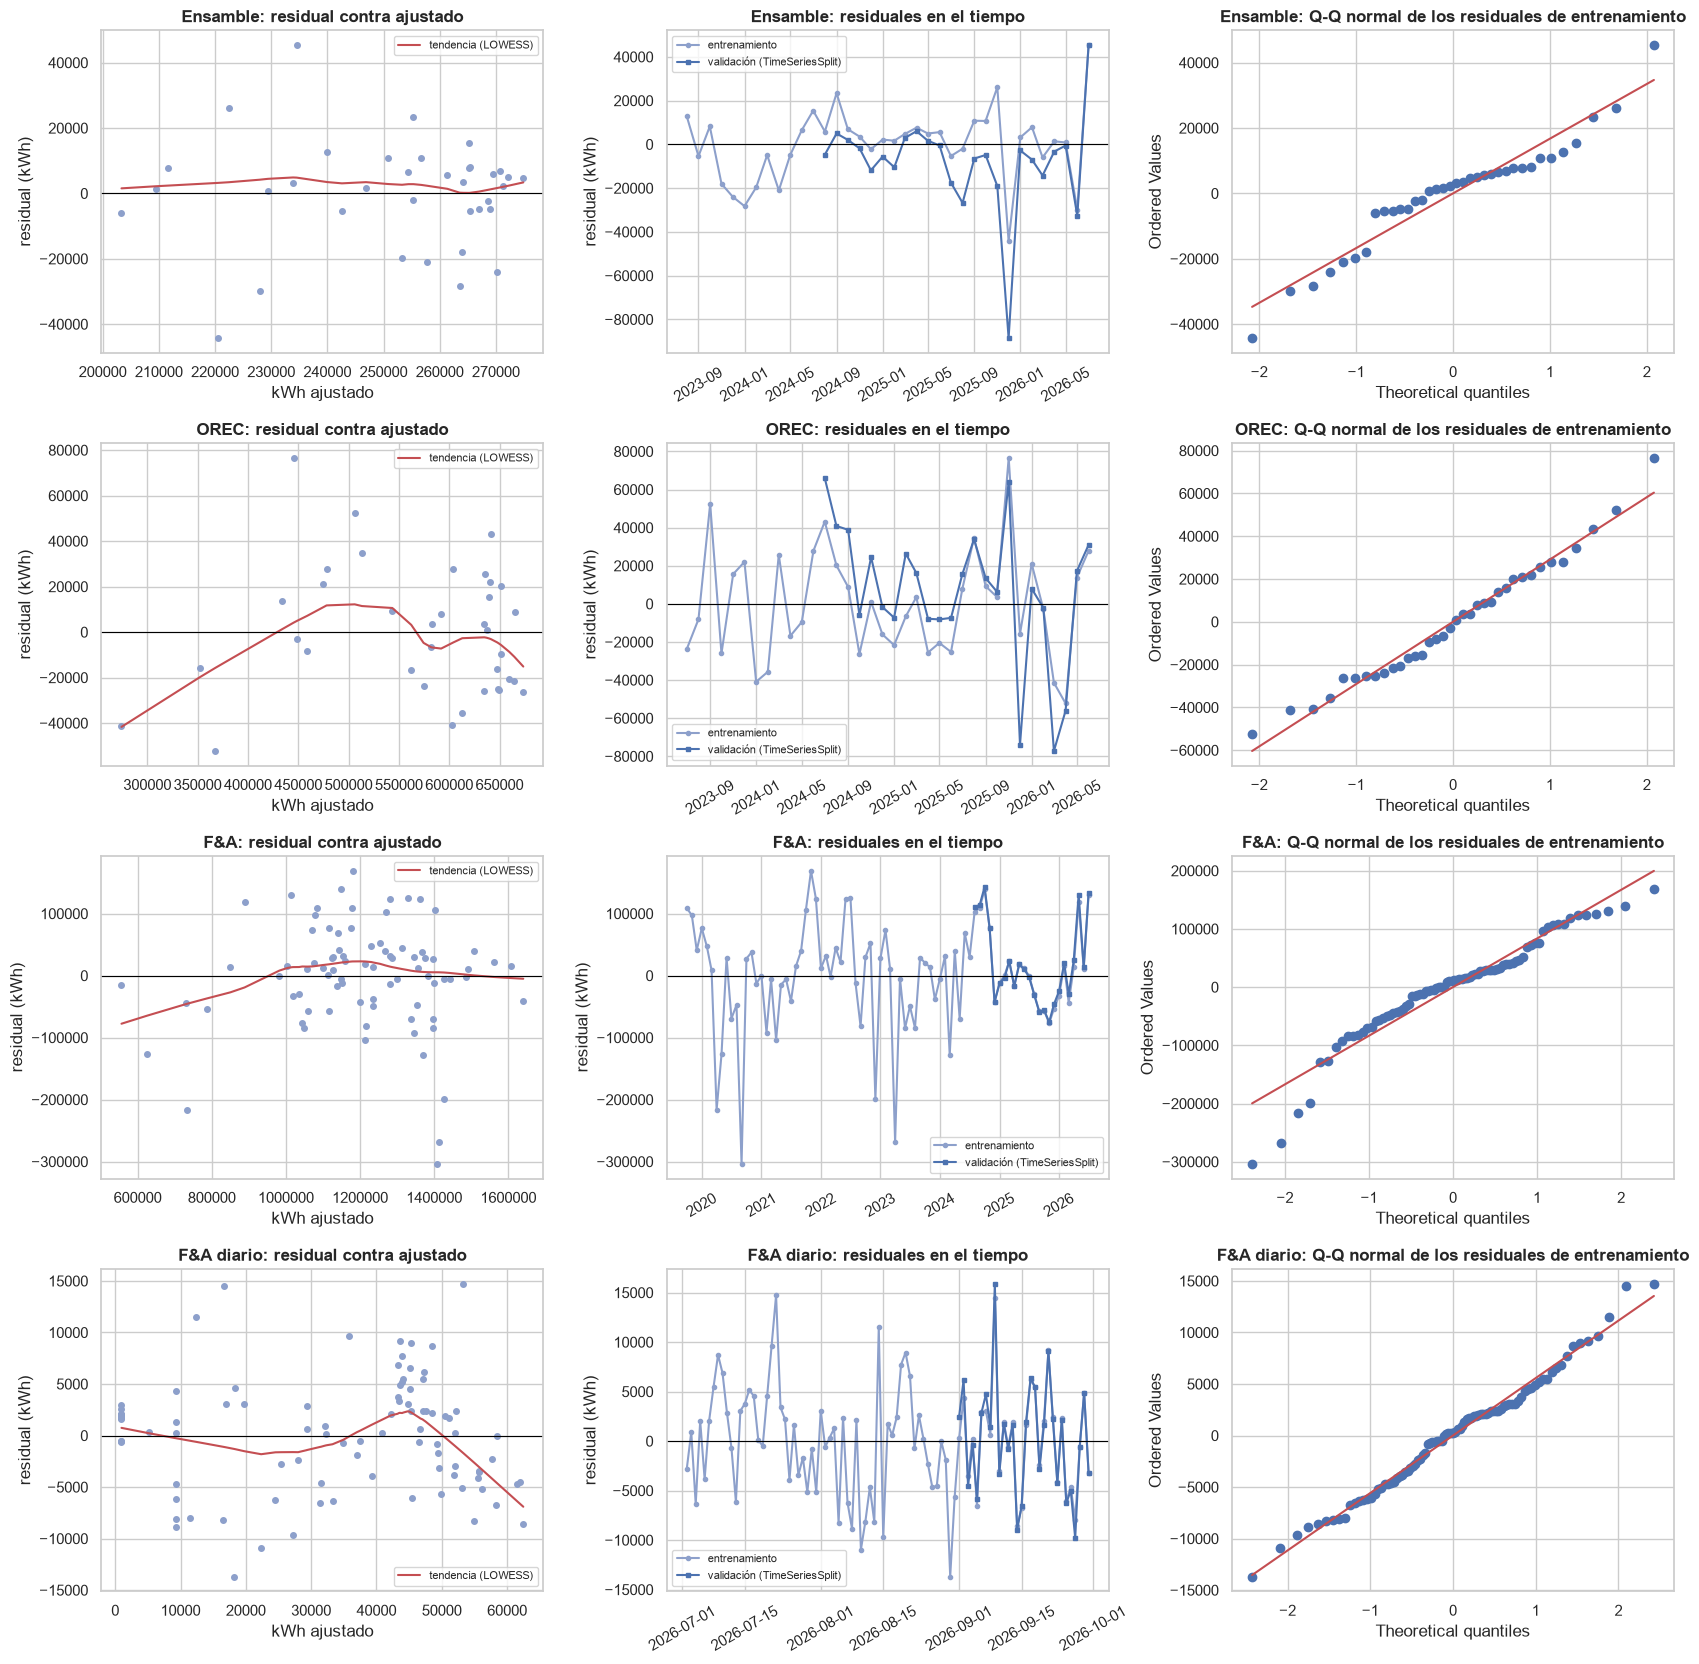

In [34]:
fig, axes = plt.subplots(len(final_fits), 3, figsize=(17, 4.2 * len(final_fits)))
for row, (name, fit) in zip(axes, final_fits.items(), strict=True):
    residuals = fit.resid
    forecasts, actual = backtests[name]
    validation_errors = actual - forecasts["Pipeline"]["pred"]

    row[0].scatter(fit.fittedvalues, residuals, s=16, color="#8DA0CB")
    trend = sm.nonparametric.lowess(residuals, fit.fittedvalues, frac=0.6)
    row[0].plot(trend[:, 0], trend[:, 1], color="#C44E52", lw=1.5, label="tendencia (LOWESS)")
    row[0].axhline(0, color="black", lw=0.8)
    row[0].set(title=f"{name}: residual contra ajustado", xlabel="kWh ajustado")
    row[0].set_ylabel("residual (kWh)")
    row[0].ticklabel_format(style="plain")
    row[0].legend(fontsize=8)

    row[1].plot(
        residuals.index, residuals, color="#8DA0CB",
        marker="o", ms=3, label="entrenamiento")
    row[1].plot(
        validation_errors.index,
        validation_errors,
        color="#4C72B0",
        marker="s",
        ms=3,
        label="validación (TimeSeriesSplit)",
    )
    row[1].axhline(0, color="black", lw=0.8)
    row[1].set(title=f"{name}: residuales en el tiempo", ylabel="residual (kWh)")
    row[1].ticklabel_format(axis="y", style="plain")
    row[1].tick_params(axis="x", labelrotation=30)
    row[1].legend(fontsize=8)

    stats.probplot(residuals, dist="norm", plot=row[2])
    row[2].set_title(f"{name}: Q-Q normal de los residuales de entrenamiento")
    row[2].ticklabel_format(style="plain")
plt.tight_layout()
plt.show()

**Explicación técnica.**

* **Sin sobreajuste.** El WAPE de validación es igual o menor que el de entrenamiento en tres de los cuatro casos:

  | Caso | WAPE de entrenamiento | WAPE de validación |
  |---|---|---|
  | Ensamble | 6.55 % | 5.34 % |
  | F&A | 5.08 % | 4.72 % |
  | F&A diario | 13.22 % | 12.28 % |

  * **OREC es la excepción:** 3.82 % en entrenamiento contra 4.89 % en validación, una brecha de 1.08 puntos (razón 1.28). Es moderada y deja a OREC en menos de la mitad del error del ingenuo (10.21 %).
  * **El R² de validación** es mayor o igual que el de entrenamiento salvo en el diario, con una diferencia mínima (0.93 contra 0.90).
  * **Con dos o tres variables** el modelo casi no tiene capacidad de memorizar.
* **Valores p (HAC Newey-West) del modelo final.**
  * **`eq` es significativa en los cuatro casos** (p < 0.001), con intervalos estrechos:
    * Ensamble: 0.69 kWh/EQ (0.51 a 0.88);
    * OREC: 4.79 (4.21 a 5.37);
    * F&A: 16.78 (14.76 a 18.80);
    * F&A diario: 15.39 (13.12 a 17.66).
  * **`dias` es significativa** en Ensamble (p = 0.018) y F&A (p = 0.045), y no en OREC (p = 0.108).
  * **El intercepto** es significativo salvo en F&A mensual (p = 0.071): F&A nunca opera cerca de cero EQ, así que su carga fija es una extrapolación imprecisa. El intercepto de esta tabla es el consumo con cero EQ en un mes de días promedio; por eso no coincide con los «kWh fijos de un mes de 30 días» de la sección 7.
  * **En el diario,** `domingo` es significativo (−8,335 kWh, p = 0.017) y `sin_eq` no (p = 0.624). Un día sin EQ que no es domingo no consume distinto de lo que ya predice su producción cero, así que esa variable podría quitarse.
  * **Errores HAC y MCO clásico pueden dar conclusiones distintas.** `dias` en Ensamble tiene p = 0.018 con HAC y 0.069 con MCO; el intercepto de F&A, 0.071 con HAC y 0.018 con MCO. Con series de tiempo se reporta la versión HAC.
* **Residuales.**
  * **Ensamble pasa todas las pruebas:** Jarque-Bera p = 0.324, Breusch-Pagan p = 0.101, RESET p = 0.534, Ljung-Box p = 0.974, DW 1.79.
  * **OREC** rechaza RESET (p = 0.005): la curva LOWESS muestra algo de curvatura en el rango medio de consumo.
  * **F&A mensual** rechaza tres pruebas:
    * normalidad (Jarque-Bera p < 0.001), por una cola izquierda de pocos meses muy por debajo de lo esperado, visible en el Q-Q;
    * RESET (p = 0.010);
    * independencia (Ljung-Box p = 0.028, DW 1.44).

    Esa autocorrelación explica por qué los errores AR(1) mejoraron a F&A en la sección 5 (MASE 0.49 contra 0.55), y es la razón de usar errores HAC.
  * **El diario** muestra heterocedasticidad (Breusch-Pagan p = 0.025), que los errores HAC corrigen; Ljung-Box queda en el límite (p = 0.054).

**Lectura de negocio.**

* **El modelo no memoriza.** En los meses que nunca vio se equivoca lo mismo, o menos, que en los meses con los que aprendió. Por eso se puede esperar que su precisión de alrededor del 5 % se mantenga al usarlo cada mes.
* **El volumen es lo único que pesa siempre.** En las cuatro versiones el efecto de los EQ es claramente distinto de cero, y lo que cuesta cada EQ adicional está bien medido: unos 0.7 kWh en Ensamble, 4.8 en OREC y 16.8 en F&A.
* **Un domingo en F&A** consume unos 8,335 kWh menos de lo que su producción explicaría. Un día sin producción entre semana no se distingue de un día normal con producción cero.
* **Dónde ser prudentes.**
  * **La carga fija mensual de F&A** está mal medida (intervalo de −10,524 a 256,191 kWh), así que no se debe citar como un número firme. El costo por EQ de F&A sí es sólido.
  * **En OREC y F&A** la línea recta no captura toda la curvatura en los volúmenes extremos. La banda de alerta se debe revisar cuando el volumen salga del rango histórico.